# [이론] 공변량 — 공휴일 열을 미래 입력으로

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 공변량이 필요한가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">공변량 — 공휴일 열을 미래 입력으로</h1>
<div style="font-size:1.05em;color:#656565">공휴일처럼 미리 아는 정보를 Chronos-2 에 입력하면 서울 지하철 100개 역의 예측은 어떻게 달라지는가</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 공휴일 정보를 추가하면 예측이 좋아지는가 [필수]

서울 지하철 100개 역의 앞으로 7일 승차 인원을 역마다 예측합니다. 역 운영팀은 이 예측으로 역마다 인력을 정합니다.

제로샷을 배울 때 Chronos-2 는 과거 승차 인원만 입력해 예측했습니다. 그래서 평일 공휴일도 여느 평일과 같은 크기로 예측했습니다.

채점한 다섯 주에는 평일 공휴일이 6일 있었습니다. 광복절, 개천절, 추석 연휴 이틀, 설 연휴 이틀입니다.

이 6일에 100개 역의 예측을 모두 더하면 실제 승차 인원의 2.14배였습니다. 이 예측대로 인력을 배치하면 공휴일마다 인력이 크게 남습니다.

그런데 공휴일은 달력으로 미리 알 수 있습니다. 예를 들어 다음 주 월요일과 화요일이 설 연휴라는 사실은 예측하기 전에 이미 알고 있습니다.

따라서 이 수업의 핵심 질문은 하나입니다.

> 공휴일 정보를 Chronos-2 에 함께 입력하면, 서울 지하철 100개 역의 7일 승차 인원 예측이 좋아지는가?

결론부터 말하면 세 가지입니다.

- 공휴일이 있는 주에는 예측이 크게 좋아졌습니다.
- 공휴일이 없는 주에는 좋아졌다고 보기 어렵습니다.
- 따라서 평균 하나로 정하지 않고, 공휴일이 있는 주와 없는 주를 나눠서 판단합니다.

### 공변량이란 무엇인가 [필수]

먼저 작은 예시로 설명합니다. 가게 한 곳의 하루 손님 수를 예측한다고 하겠습니다.

| 주 | 월 | 화 | 수 | 목 | 금 | 토 | 일 | 휴일 |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| 1주(1～7일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 | 없음 |
| 2주(8～14일째) | 100 | 100 | 20 | 100 | 100 | 60 | 40 | 수요일 |
| 3주(15～21일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 | 없음 |
| 4주(22～28일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 | 없음 |
| 다음 주(29～35일째) | ? | ? | ? | ? | ? | ? | ? | 수요일 |

표의 수는 하루 손님 수(명)입니다.

지금은 29일째 아침이고, 다음 주 7일(29～35일째)의 손님 수를 예측합니다.

예측하는 이때를 **예측 시점**이라고 합니다. 지금까지 예측 원점이라고 부른 날의 아침입니다.

다음 주 수요일도 휴일이고, 그날의 실제 손님 수도 20명이라고 가정합니다.

과거 손님 수만 입력하면 지난 네 수요일의 100 · 20 · 100 · 100명을 가중 평균해 예측합니다. Chronos-2 의 어텐션을 배울 때 한 계산입니다.

$$
(4 \times 100 + 1 \times 20 + 4 \times 100 + 4 \times 100) \div 13 = 1{,}220 \div 13 \approx 93.8 \text{ 명}
$$

휴일이던 수요일의 20명은 13분의 1 만 반영되어, 예측값은 100명에 가까운 93.8명입니다.

그런데 그날의 실제 손님 수는 20명입니다. 예측이 실제보다 73.8명 높습니다.

과거 손님 수에는 다음 수요일이 휴일이라는 정보가 없기 때문입니다.

<details class="lms-extra"><summary>자세히 — 93.8명의 계산</summary>

식에서 손님 수에 곱한 4 와 1 은 주마다 가중치의 비입니다.

휴일이던 2주는 손님 수의 모양이 다른 주와 다릅니다. 그래서 2주를 1, 나머지 세 주를 4 의 비로 반영합니다. 나머지 세 주를 2주보다 4배 크게 반영한다는 뜻입니다.

나누는 수 13 은 네 주의 비를 모두 더한 값입니다.

이 비는 Chronos-2 의 어텐션을 배울 때 계산한 값입니다.

먼저 주마다 요일별 손님 수의 모양을 4주와 비교해 유사도를 계산했습니다. 1주 · 3주 · 4주의 유사도는 7 이고, 수요일의 모양이 다른 2주는 5 입니다.

다음으로 유사도가 1 높을 때마다 가중치의 비를 2배로 했습니다. 2주는 유사도가 2 낮아, 나머지 세 주의 비가 2주의 2 × 2 = 4배입니다.

| 주 | 수요일 손님 수 | 유사도 | 가중치의 비 | 가중치(비 ÷ 13) |
|---|---:|---:|---:|---:|
| 1주 · 3주 · 4주 | 100명 | 7 | 4 씩 | 4 ÷ 13 ≈ 0.31 씩 |
| 2주(수요일 휴일) | 20명 | 5 | 1 | 1 ÷ 13 ≈ 0.08 |

100명이던 세 주의 가중치가 0.31 씩이라, 예측값은 100명에 가깝습니다. 20명이던 2주는 가중치 0.08 로만 반영됩니다.

</details>

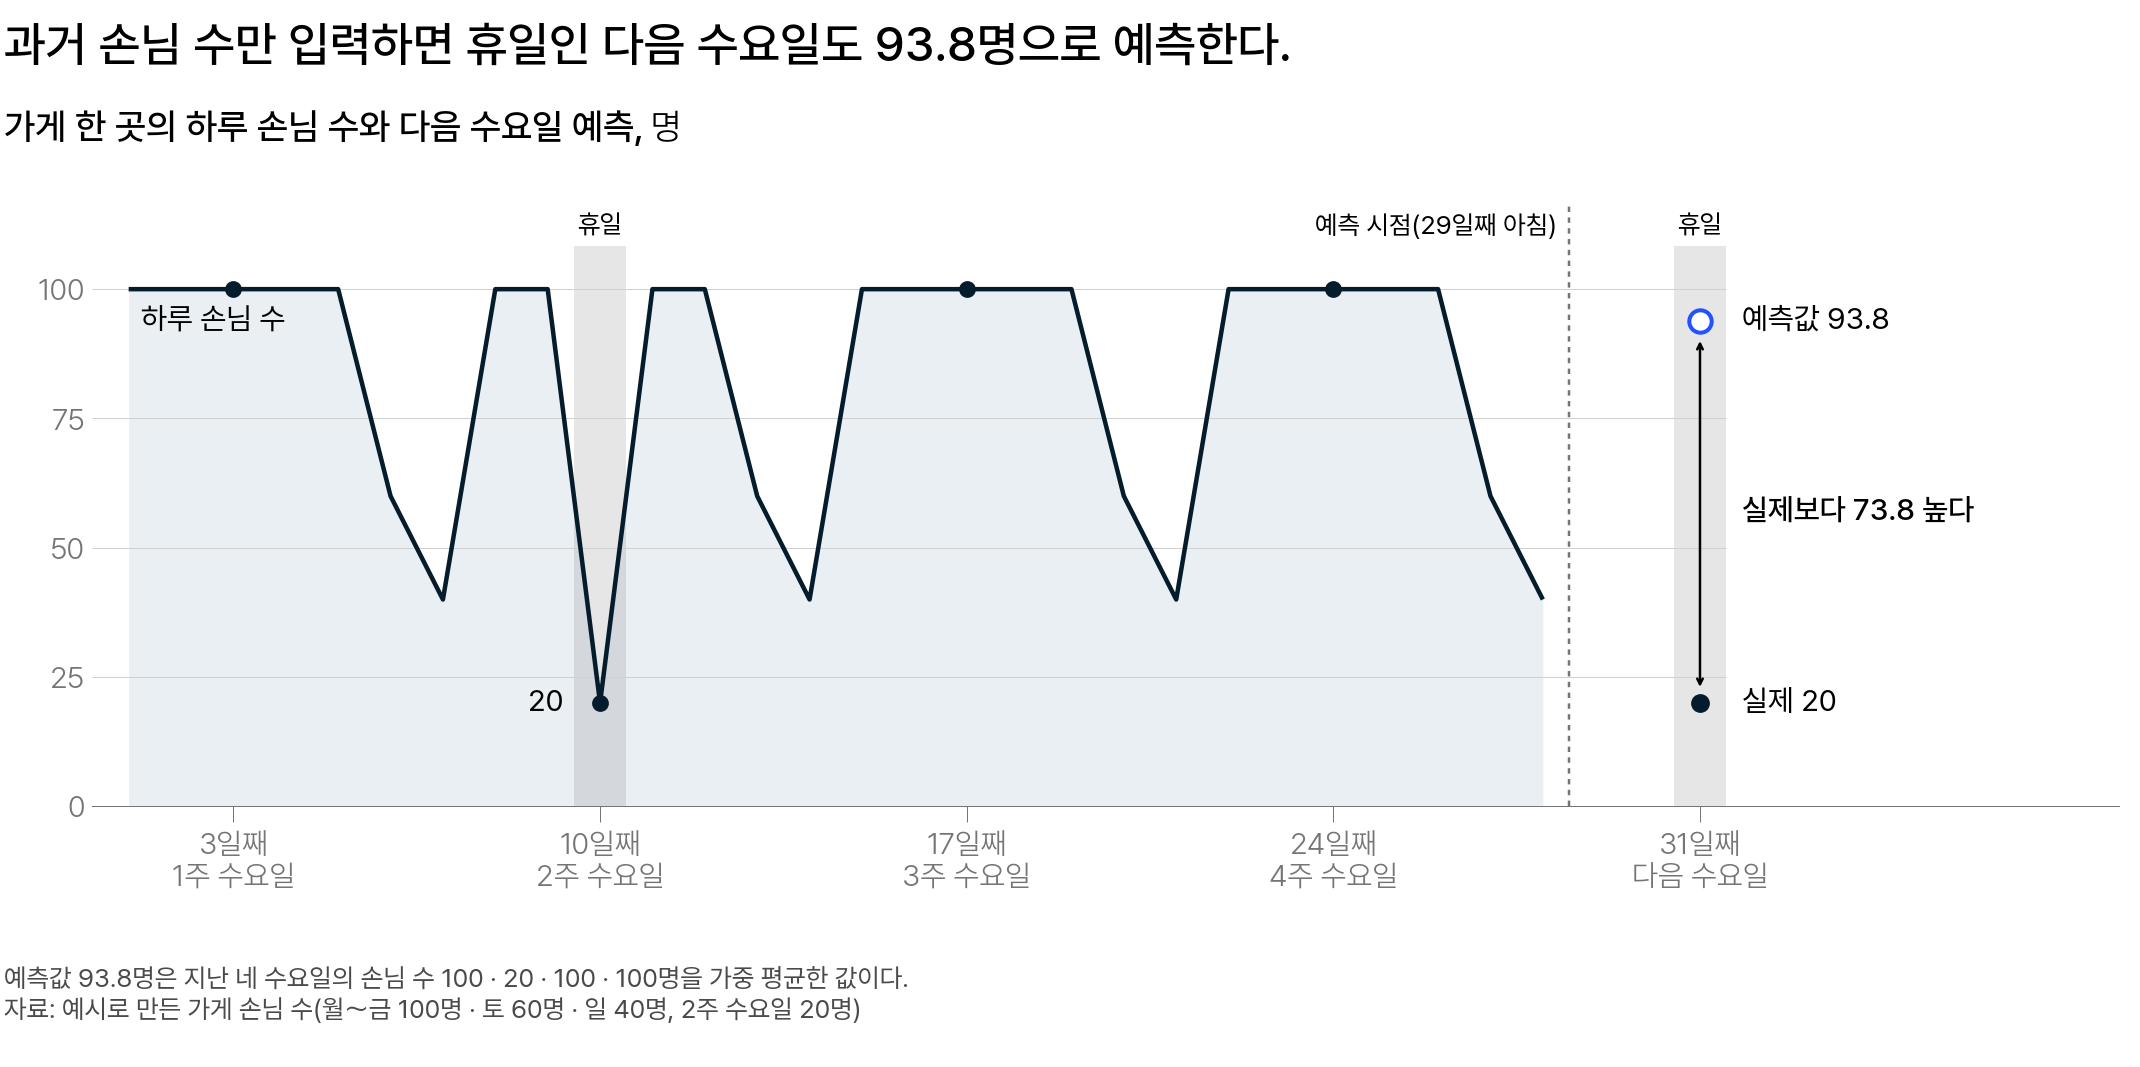

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 과거 손님 수만 입력한 다음 수요일(31일째) 예측값은 93.8명이고, 휴일인 그날의 실제 손님 수는 20명이다</em></p>

하지만 다음 수요일이 휴일이라는 사실은 달력으로 이미 알고 있습니다. 그래서 휴일 여부를 휴일이면 1, 아니면 0 인 **휴일 열**로 만들어 손님 수와 함께 모델에 전달합니다.

여기서 휴일 여부처럼 함께 입력하는 열을 **공변량(covariate)** 이라고 합니다.

> 공변량은 예측하려는 값과 함께 모델에 입력하는 다른 열입니다.

회귀의 설명변수, Prophet 의 외생 변수와 같은 것이고, 딥러닝 시계열 도구에서는 공변량이라고 부릅니다.

예측하려는 값은 손님 수이고, 공변량은 입력으로만 씁니다. 공변량의 값은 예측하지 않습니다.

공변량이 없으면 다음 수요일이 평일이어도 휴일이어도 입력한 값이 같습니다. 그래서 예측값도 93.8명으로 같습니다. 과거 손님 수만으로는 **휴일인 수요일을 평일인 수요일과 구별할 수 없습니다**.

휴일 열을 함께 입력하면, 다음 수요일이 2주 수요일과 같은 휴일이라는 정보가 더해집니다. 2주 수요일의 손님 수는 20명이었으므로, 다음 수요일을 100명보다 낮게 예측할 근거가 됩니다.

즉, 공변량은 **예측하려는 값의 과거만으로는 알 수 없는 정보**를 예측에 더하는 열입니다.

공변량이 될 수 있는 열은 휴일 여부만이 아닙니다. 가게에는 날마다 집계하는 결제 건수와, 바뀌지 않는 좌석 수도 있습니다.

가게의 네 열은 서울 지하철 자료에서 다음 열에 해당합니다.

| 가게 예시 | 서울 지하철 |
|---|---|
| 손님 수(예측하려는 값) | 역별 승차 인원 |
| 휴일 여부 | 공휴일 여부 |
| 그날 결제 건수 | 그날 하차 인원 |
| 좌석 수 | 호선 |

가게 한 곳이 역 하나에 해당합니다.

<details class="lms-extra"><summary>더 깊이 — Prophet 의 휴일 효과와 무엇이 다른가</summary>

시계열 과목의 Prophet 은 날 $t$ 의 관측값 $y(t)$ 를 네 항과 오차항 $\varepsilon_t$ 의 합으로 나타냈습니다.

$$
y(t) = g(t) + s(t) + h(t) + \beta\, x(t) + \varepsilon_t
$$

- $g(t)$: 추세
- $s(t)$: 요일처럼 정해진 주기로 되풀이되는 계절성
- $h(t)$: 휴일 효과. 지정한 휴일에만 더하는 값
- $\beta\, x(t)$: 외생 변수 $x$ 에 계수 $\beta$ 를 곱한 항

휴일인 날의 예측은 휴일 효과만큼, 외생 변수가 있는 날의 예측은 그 항만큼 달라집니다.

<img src="https://assets.mbrenndoerfer.com/_optimized/notebooks/prophet_files/prophet-components-trend-seasonality-holidays-1920w.webp" alt="Prophet 성분 그림 — 추세, 휴일, 요일, 연중, 월간" width="450" height="635"/>
<p align="center"><em>▲ 적합이 끝난 Prophet 모형의 성분 그림. 위에서 둘째 그림(holidays)이 휴일 효과이고, 휴일마다 값의 크기가 다르다 (출처: Marcel Brenndoerfer, "Prophet: Time Series Forecasting")</em></p>

| 그림에 적힌 이름 | 뜻 |
|---|---|
| trend | 추세 $g(t)$ |
| holidays | 휴일 효과 $h(t)$. 휴일이 아닌 날은 0 이다 |
| weekly · yearly · monthly | 요일 · 한 해 · 한 달 주기의 계절성 $s(t)$ |
| ds | 날짜 |

Chronos-2 에 입력하는 휴일 열은 Prophet 의 휴일 효과와 두 가지가 다릅니다.

| 항목 | Prophet 의 휴일 효과 | Chronos-2 에 입력하는 휴일 열 |
|---|---|---|
| 학습하는 것 | 이 자료로 휴일마다 계수를 학습해 더한다 | 계수를 학습하지 않고, 입력한 과거의 휴일 값과 그날 손님 수에서 얻는다 |
| 휴일마다 크기가 다른가 | 휴일마다 계수가 따로 있다 | 0 과 1 뿐인 열이라 휴일의 종류가 구별되지 않는다 |

즉, Prophet 은 휴일마다 다른 크기를 학습하고, 휴일 열은 휴일인지 아닌지만 전달합니다. 휴일의 종류가 구별되지 않아 생기는 한계는 「2. 공휴일 열과 미래 입력」에서 다룹니다.

</details>

<div class="lms-summary">

**정리**

과거 손님 수만으로 예측하면 다음 수요일이 휴일이어도 평일일 때와 같은 값이 나옵니다. 휴일 여부처럼 예측하려는 값과 함께 입력하는 열이 공변량입니다.

새 예측 과제를 받으면 달력이나 일정으로 미리 아는 정보가 무엇인지부터 찾아봅니다.

</div>

## 1. 공변량 세 종류와 누수

공변량으로 쓸 수 있는 열과 쓰면 안 되는 값은 어떻게 구별할까요?

### 공변량의 세 가지 종류 [필수]

가게에는 손님 수 말고도 휴일 여부, 기온, 결제 건수, 좌석 수 같은 열이 있습니다.

그런데 이 열들을 모두 같은 방법으로 쓸 수는 없습니다. 다음 주의 값을 아는 열도 있고, 모르는 열도 있기 때문입니다.

그래서 열마다 두 가지를 확인합니다.

1. 날마다 값이 바뀌는가?
2. 예측 시점에 예측할 날의 값을 이미 알고 있는가?

이 가게에서 예측할 날은 다음 주 7일(29～35일째)입니다.

날마다 값이 바뀌는 열은 둘째 기준에 따라 둘로 나뉩니다.

**미래 공변량(known future covariates)** 은 예측할 날의 값까지 미리 아는 열입니다.

| 예시 | 다음 주의 값을 아는 방법 |
|---|---|
| 휴일 여부 · 요일 | 달력 |
| 기온 예보 | 29일째 아침까지 발표된 예보 |

이런 열은 다음 주 7일의 값까지 함께 입력합니다.

**과거 공변량(past covariates)** 은 지난날의 값은 있지만 예측할 날의 값은 아직 모르는 열입니다.

| 예시 | 다음 주의 값을 모르는 까닭 |
|---|---|
| 그날 결제 건수 | 그날 영업이 끝나야 집계된다 |
| 실측 기온 | 그날이 지나야 측정된다 |

이런 열은 28일째까지의 값만 씁니다.

다음 주의 값을 모르는 열도 예측에 쓰는 까닭이 있습니다. 지난날의 값이 손님 수와 함께 움직였다면, 손님 수의 과거를 설명하는 정보가 되기 때문입니다.

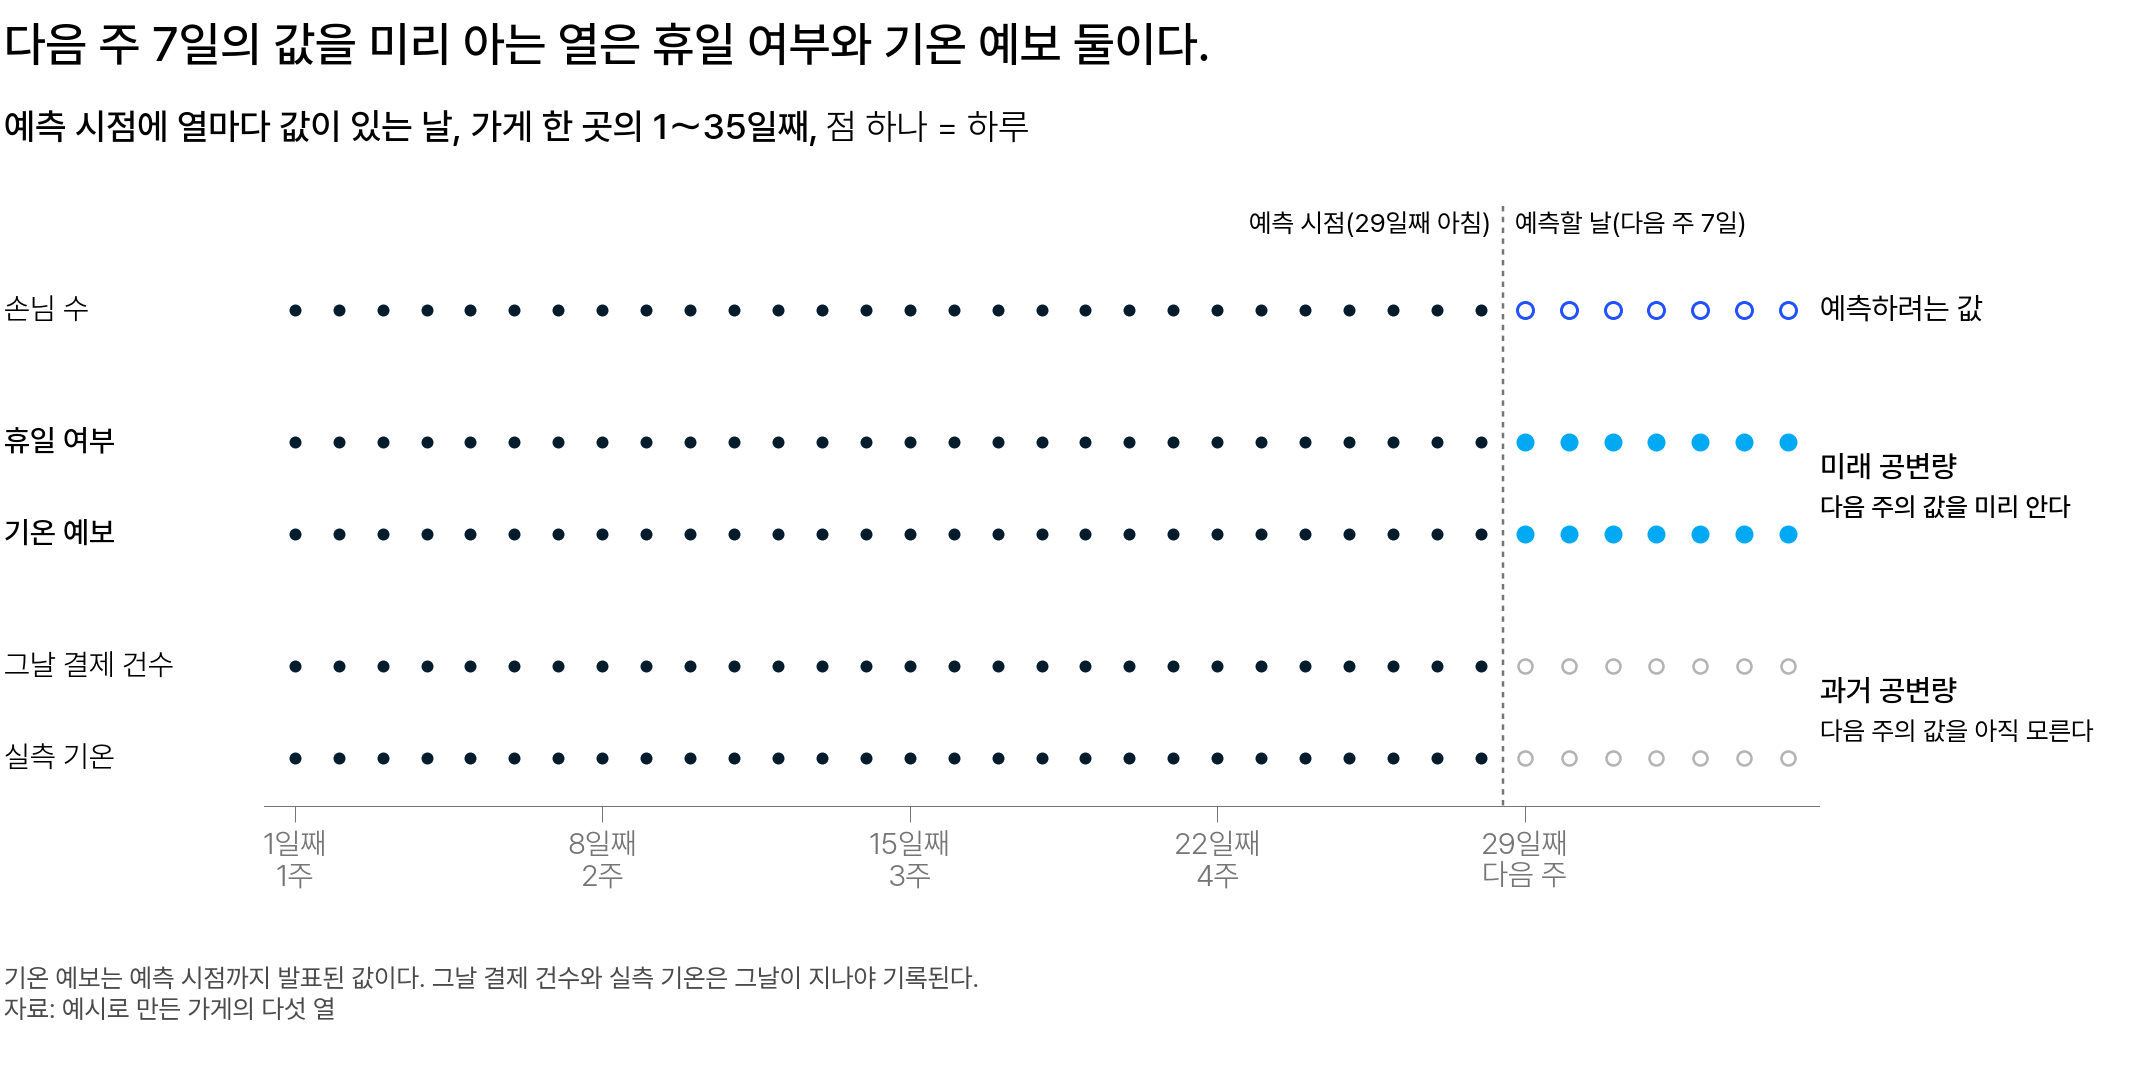

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 세로 점선이 예측 시점(29일째 아침)이다. 휴일 여부와 기온 예보만 다음 주 7일까지 값이 있다</em></p>

같은 기온이라도 예보는 미래 공변량이고, 실측은 과거 공변량입니다. 즉, 종류는 열의 이름보다 둘째 기준으로 정해집니다.

**정적 공변량(static covariates)** 은 날이 바뀌어도 값이 같은 열입니다. 가게의 좌석 수, 서울 지하철이면 역의 호선이 여기에 해당합니다.

정적 공변량으로는 날마다의 변화를 설명할 수 없습니다. 대신 가게마다, 역마다 다른 특성을 나타냅니다.

세 종류를 표 하나로 정리합니다.

| 종류 | 날마다 값이 바뀌는가 | 예측할 날의 값을 미리 아는가 | 가게 예시 | 서울 지하철 |
|---|---|---|---|---|
| 미래 공변량 | 바뀐다 | 안다 | 휴일 여부 · 기온 예보 | 요일 · 공휴일 여부 · 기온 예보 |
| 과거 공변량 | 바뀐다 | 모른다 | 그날 결제 건수 · 실측 기온 | 그날 하차 인원 · 실측 기온 |
| 정적 공변량 | 바뀌지 않는다 | 늘 같은 값이다 | 좌석 수 | 호선 |

다른 예측 과제의 열도 같은 기준으로 나눕니다. 매장 매출을 예측한다면 이렇게 나뉩니다.

- 판촉 일정은 미리 정해져 있으므로 미래 공변량입니다.
- 그날 방문 손님 수는 그날이 지나야 알므로 과거 공변량입니다.
- 매장 위치는 날이 바뀌어도 같으므로 정적 공변량입니다.

여기서 흔한 실수는 지난 자료 파일에 값이 있으면 미래 공변량이라고 생각하는 것입니다. 그러나 파일의 실측 기온은 그날이 지난 뒤에 기록된 값입니다.

즉, 예측할 날의 값까지 입력하는 것은 **미래 공변량뿐**입니다. 과거 공변량은 **예측 시점 전날까지의 값만** 씁니다.

<details class="lms-extra"><summary>더 깊이 — Darts 문서의 공변량 그림 읽기</summary>

Darts 는 시계열 예측 모델 여럿을 같은 사용법으로 쓰는 파이썬 라이브러리입니다.

아래는 그 문서의 그림이고, 예측 시점을 기준으로 세 입력이 어느 날까지 이어지는지 보입니다.

<img src="https://unit8co.github.io/darts/_images/top_level.png" alt="예측 시점을 기준으로 target, past_covariates 는 과거까지, future_covariates 는 예측할 이틀까지 이어지는 그림" width="640" height="287"/>
<p align="center"><em>▲ 예측 시점(prediction point)을 기준으로 본 세 입력. 위의 두 막대는 예측 시점에서 끝나고, 맨 아래 막대만 예측할 이틀(Mon2 · Tue2)까지 이어진다 (출처: Darts 공식 문서, Covariates Figure 1)</em></p>

| 그림의 말 | 뜻 | 가게 예시 | 서울 지하철이라면 |
|---|---|---|---|
| target | 예측하려는 값 | 손님 수 | 승차 인원 |
| past_covariates | 과거 공변량 | 그날 결제 건수 | 그날 하차 인원 |
| future_covariates | 미래 공변량 | 휴일 열 | 공휴일 열 |
| prediction point | 예측 시점 | 29일째 아침 | 예측 원점(수요일)의 아침 |
| future(Mon2 · Tue2) | 예측할 날. 그림은 이틀 | 다음 주 7일 | 채점 7일 |

세 막대에서 나온 선은 모두 forecast(예측) 상자로 이어집니다. 세 입력을 함께 써서 예측한다는 뜻입니다.

그림처럼 과거 7일로 이틀을 예측하면 위의 두 입력은 값이 7개씩입니다. 반면 future_covariates 는 7 + 2 = 9개입니다.

여기서 future_covariates 를 앞날의 예측하려는 값으로 읽으면 틀립니다. future_covariates 는 예측할 날의 값을 예측 시점에 이미 아는 열입니다.

Darts 문서는 두 종류의 구별을 한 문장으로 정리합니다. 값을 미리 알면 미래 공변량이고, 모르면 과거 공변량입니다.

Chronos-2 에는 세 입력을 과거의 표와 예측할 날의 표, 두 표로 나눠 전달합니다. 두 표는 「2. 공휴일 열과 미래 입력」에서 다룹니다.

반면 공변량을 종류마다 따로 받는 모델도 있습니다.

<img src="https://ar5iv.labs.arxiv.org/html/1912.09363/assets/TemporalFusion.png" alt="Temporal Fusion Transformer 구조 — 정적 메타데이터, 과거 입력, 미래 공변량 입력" width="640" height="347"/>
<p align="center"><em>▲ Temporal Fusion Transformer(TFT)의 구조. 맨 아래 입력이 Static Metadata · Past Inputs · Known Future Inputs 셋으로 나뉜다 (출처: Lim 외, arXiv:1912.09363 Figure 2)</em></p>

Static Metadata 가 정적 공변량, Past Inputs 가 과거 공변량, Known Future Inputs 가 미래 공변량입니다.

TFT 논문은 세 입력의 예시로 매장 위치, 지난 방문 손님 수, 다가오는 공휴일 날짜를 듭니다. 본문의 매장 매출 예시와 같은 구별입니다.

이처럼 도구마다 이름은 달라도 종류를 나누는 기준은 같습니다.

</details>

### 데이터 누수란 무엇인가 [필수]

과거 공변량은 다음 주의 값을 아직 모르는 열입니다. 따라서 29일째 아침에는 다음 주의 값을 입력할 수 없습니다.

그런데 백테스트 자료에는 그 값이 이미 있습니다. 백테스트는 지난 자료에서 예측 시점을 정해 예측하고, 실제 값으로 채점하는 방법이기 때문입니다.

예를 들어 다음 주가 지난 뒤에 이 가게의 자료로 백테스트를 한다고 하겠습니다. 자료에는 다음 수요일(31일째)의 손님 수 20명과 결제 건수 19건이 있습니다.

손님이 20명인 날 결제가 19건이듯이, 결제 건수는 손님 수와 거의 같은 값입니다. 그래서 다음 수요일의 결제 건수 19건을 입력하면 예측도 실제와 거의 같아집니다. 여기서는 예측값이 19명이라고 하겠습니다.

| 입력한 것 | 다음 수요일 예측값 | 실제 20명과의 차이 |
|---|---:|---:|
| 과거 손님 수 | 93.8명 | 73.8명 |
| 과거 손님 수와 다음 수요일의 결제 건수 | 19명 | 1명 |

결제 건수를 함께 쓰자 오차가 73.8명에서 1명으로 줄었습니다.

하지만 29일째 아침에는 다음 수요일의 결제 건수를 알 수 없습니다.

따라서 오차 1명은 실제로 예측할 때는 얻을 수 없는 점수입니다. 이것이 **데이터 누수(data leakage)** 입니다.

> 데이터 누수는 예측 시점에는 알 수 없는 값을 입력해 백테스트 점수만 좋아지는 것입니다.

시계열 과목에서 배운 데이터 누수와 같은 뜻입니다.

누수가 있으면 백테스트 점수와 실제로 예측할 때의 오차가 달라집니다. 이런 점수로 모델을 고르면, 실제로는 쓸 수 없는 예측을 고르게 됩니다.

**휴일 여부는 왜 누수가 아닐까요?** 휴일 여부도 다음 주의 값입니다. 그런데 달력으로 이미 알고 있습니다. 따라서 다음 주의 값까지 입력해도 누수가 아닙니다.

판단 기준은 세 종류를 나눌 때와 같습니다. 예측 시점에 그 값을 이미 알고 있는지를 봅니다.

이 기준으로 보면 다음은 누수가 아닙니다.

- 이미 정해진 공휴일
- 미리 정해진 행사 일정
- 이미 발표된 기온 예보

다만 임시공휴일은 정부가 발표한 날부터 공휴일 열에 반영합니다. 예측한 뒤에 발표된 임시공휴일은 그 예측에 쓰지 않습니다.

반면 다음 값을 예측할 날까지 입력하면 누수입니다.

- 실제 하차 인원
- 실제 결제 건수

같은 결제 건수라도 28일째까지의 값은 써도 됩니다. 예측 시점에 이미 집계된 값이라, 과거 공변량으로 쓰는 것은 누수가 아닙니다. 즉, 누수는 열의 종류보다 **어느 날의 값을 입력했는지**로 결정됩니다.

실측 기온도 그날이 지나야 아는 값입니다. 다만 기온에는 결제 건수와 달리 예보가 있어, 운영에서는 예보를 씁니다.

예보 대신 실측 기온을 써서 얻은 예측은 시계열 과목에서 배운 **사후 예측(ex-post forecast)** 입니다. 사후 예측의 점수는 예보가 정확히 맞았을 때의 오차입니다.

하지만 예보는 틀릴 수 있습니다. 따라서 실측 기온을 입력한 점수는 사후 예측의 점수로 구분합니다. 이 점수를 운영에서 얻을 오차로 쓰면 누수입니다.

즉, 백테스트 점수가 좋아졌다면 **그 값을 예측 시점에 알 수 있었는지**부터 확인합니다.

<details class="lms-extra"><summary>더 깊이 — 사전 예측과 사후 예측</summary>

fpp3 는 시계열 예측 교재 『Forecasting: Principles and Practice』의 약칭입니다.

fpp3 는 예측을 공변량으로 입력한 값에 따라 둘로 나눕니다.

| 이름 | 공변량으로 입력한 값 | 점수의 뜻 |
|---|---|---|
| 사전 예측(ex-ante forecast) | 예측 시점에 아는 값(달력 · 예보) | 실제로 예측할 때의 오차 |
| 사후 예측(ex-post forecast) | 나중에 안 실제 값(실측) | 공변량 값이 맞았을 때의 오차 |

예를 들어 기온을 공변량으로 써서 여름 수요일 하루를 예측한다고 하겠습니다. 그날의 실제 손님 수는 108명입니다.

| 입력한 기온 | 예측값 | 실제 108명과의 차이 | 이 오차의 뜻 |
|---|---:|---:|---|
| 그 아침의 예보 25도(사전 예측) | 100명 | 8명 | 실제로 예측할 때의 오차 |
| 나중에 안 실측 30도(사후 예측) | 110명 | 2명 | 기온 예보가 맞았을 때의 오차 |

fpp3 는 두 예측을 비교하면 오차가 예보 때문인지 모델 때문인지 알 수 있다고 설명합니다.

이 예시에서는 8명 가운데 6명이 기온 예보가 5도 낮아서 생긴 오차입니다. 남은 2명은 기온을 정확히 알아도 생기는 오차입니다.

사후 예측은 도구의 예제에도 나옵니다. AutoGluon 문서의 Chronos-2 안내서는 전력 수요 예제에 실측 날씨를 입력합니다. 그리고 실제로는 날씨 예보를 쓴다고 함께 설명합니다.

반면 휴일 열은 예측 시점에 달력으로 이미 알아, 사전 예측과 사후 예측이 같습니다.

<img src="https://otexts.com/fpp3/regression_files/figure-html/fig-ConsInc4-1.png" alt="미국 소비 증가율의 시나리오별 예측 — 소득·저축이 늘 때와 줄 때" width="640" height="395"/>
<p align="center"><em>▲ 미국 소비 증가율을 공변량 값의 두 시나리오로 예측한 그림. 소득 1% · 저축 0.5% 증가(파랑)와 같은 크기의 감소(주황)에서 예측이 크게 다르다 (출처: Hyndman · Athanasopoulos, Forecasting: Principles and Practice 3rd ed., 7.6 Figure 7.18)</em></p>

| 그림에 적힌 이름 | 뜻 |
|---|---|
| US consumption · % change | 미국 소비의 분기 증가율(%) |
| Scenario: Increase · Decrease | 공변량 값을 늘린 시나리오(파랑) · 줄인 시나리오(주황) |
| level 80% · 95% | 예측 구간의 수준. 진한 색이 80% 구간이다 |
| Quarter | 분기 |

fpp3 는 이 그림의 구간에 공변량 값이 틀릴 가능성은 반영되지 않았다고 설명합니다. 예보를 입력한 예측의 구간도 예보가 맞는다고 보고 계산한 구간입니다.

원문은 [fpp3 7.6 「Forecasting with regression」](https://otexts.com/fpp3/forecasting-regression.html) 입니다.

</details>

> **[문제] 세 종류로 나누기**
>
> 요일, 공휴일, 호선, 그날 하차 인원, 기온 예보, 실측 기온을 세 종류로 바르게 나눈 것은 무엇인가요?
>
> 1. 정적: 호선 / 미래: 요일·공휴일·기온 예보 / 과거: 그날 하차 인원·실측 기온
> 2. 정적: 호선 / 미래: 요일·공휴일·기온 예보·실측 기온 / 과거: 그날 하차 인원
> 3. 정적: 호선 / 미래: 요일·기온 예보 / 과거: 공휴일·그날 하차 인원·실측 기온

<div class="lms-summary">

**정리**

열은 예측할 날의 값을 미리 아는지에 따라 미래 공변량과 과거 공변량으로 나누고, 날이 바뀌어도 값이 같으면 정적 공변량입니다. 예측 시점에 모르는 값을 입력하면 백테스트 점수만 좋아지는 데이터 누수가 생깁니다.

**할 일**

- 휴일 여부처럼 달력으로 아는 열은 예측할 날의 값까지 입력합니다
- 결제 건수 같은 과거 공변량은 예측 시점 전날까지의 값만 씁니다
- 실측 기온을 입력한 백테스트 점수는 사후 예측의 점수로 구분합니다

서울 지하철에서는 공휴일 열이 미래 공변량이고, 그날 하차 인원이 과거 공변량입니다.

</div>

> **[문제] 공휴일은 달력으로 미리 아는 값이라, 채점 7일의 공휴일 값을 입력해도 누수가 아니다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 2. 공휴일 열과 미래 입력

가중치를 고치지 않는 Chronos-2 에 공휴일 정보를 어떻게 전달하고, 그러면 예측은 어떻게 달라질까요?

### Chronos-2 에 공휴일 정보를 전달하는 방법 [필수]

가게 예시의 휴일 열로 먼저 설명합니다. 서울 지하철에서는 이 열이 공휴일 열입니다.

휴일 열은 미래 공변량이고, 미래 공변량은 예측할 날의 값까지 입력하는 열입니다. Prophet 에서 외생 변수를 학습 표와 예측 표 양쪽에 포함한 것과 같습니다.

그런데 가게의 두 열은 값이 있는 날이 다릅니다. 손님 수는 28일째까지만 있고, 휴일 열은 다음 주 7일의 값도 있습니다.

그래서 Chronos-2 에는 표를 둘로 나눠 전달합니다. 예측 시점 전날까지의 값은 **과거 표 `df`** 에, 예측할 7일의 값은 **미래 입력 `future_df`** 에 있습니다.

| 표 | 날짜 `timestamp` | 손님 수 `target` | 휴일 열 `holiday` |
|---|---|---|---|
| 과거 표 `df`(28행) | 1～28일째 | 있음 | 있음 |
| 미래 입력 `future_df`(7행) | 29～35일째 | 열 없음 | 있음 |

표에서 보듯 미래 입력에는 `target` 열이 없습니다. `target` 은 예측하려는 값이기 때문입니다.

이때 열의 종류는 따로 지정하지 않습니다.

> 두 표에 모두 있는 열은 미래 공변량으로, 과거 표에만 있는 열은 과거 공변량으로 받습니다.

여기서 생기기 쉬운 실수는 휴일 열을 과거 표에만 포함하고 미래 입력을 빠뜨리는 것입니다. 이렇게 해도 오류는 나지 않습니다. Chronos-2 가 휴일 열을 과거 공변량으로 받기 때문입니다.

그러면 지난 휴일의 값만 전달되고, 다음 수요일이 휴일인지는 전달되지 않습니다. 따라서 예측하기 전에 미래 입력에 휴일 열이 있는지 확인합니다.

즉, 다음 주의 휴일 값은 **미래 입력 `future_df`** 로 전달합니다. 예측 시점에 이미 아는 값이므로 누수가 아닙니다.

<details class="lms-extra"><summary>자세히 — 두 표의 규칙과 다른 도구의 이름</summary>

미래 입력에만 있고 과거 표에 없는 열은 오류가 납니다. 미래 입력의 열은 과거 표에도 있어야 합니다.

Chronos-2 가 받는 표는 이 둘뿐이고, 정적 공변량만 따로 받는 표는 없습니다. 그래서 이 과정에서는 서울 지하철의 호선 열을 두 표에 포함하지 않았습니다.

열 이름을 `holiday` 대신 다른 이름으로 바꿔도 예측은 달라지지 않습니다. 열 이름은 모델에 전달되지 않습니다. 모델이 받는 것은 값이 1 인 날과 그날의 손님 수입니다.

다른 도구도 같은 구별을 합니다. Darts 는 `future_covariates`, AutoGluon 은 `known_covariates` 라는 이름으로 예측할 날의 값을 따로 받습니다.

</details>

### 어텐션은 어떤 정보를 비교하는가 [필수]

두 표로 전달한 휴일 열은 어텐션으로 예측에 반영됩니다. 어텐션은 닮은 구간의 값을 더 크게 반영하는 계산이었습니다.

먼저 Chronos-2 는 열마다 따로 16일 패치로 나눕니다. 손님 수 열의 패치와 휴일 열의 패치가 따로 있습니다.

그리고 나눈 패치를 두 방향으로 비교합니다. 아래에서는 수요일 하루로 설명하고, Chronos-2 는 16일 패치 단위로 같은 두 방향을 비교합니다.

**시간 어텐션(time attention)** 은 같은 열의 다른 시점을 비교합니다. Chronos-2 제로샷에서 배운 어텐션이 이것입니다.

예를 들어 다음 수요일을 예측할 때 손님 수 열의 지난 네 수요일을 비교합니다.

그런데 시간 어텐션은 열 하나 안에서만 계산합니다. 손님 수 열에는 다음 수요일이 휴일이라는 정보가 없고, 휴일 열에는 손님 수가 없습니다.

그래서 두 열을 잇는 계산이 하나 더 필요합니다.

**그룹 어텐션(group attention)** 은 같은 시점의 다른 열을 비교합니다.

예를 들어 2주 수요일에는 손님 수 열의 20명과 휴일 열의 1 이 같은 시점에 있습니다.

어텐션에서 서로의 값을 반영하는 열들을 **그룹(group)** 이라고 합니다. 가게 한 곳의 손님 수 열과 휴일 열이 한 그룹입니다.

기본 설정에서는 가게마다 그룹이 따로라, 옆 가게의 값은 이 가게의 예측에 쓰이지 않습니다.

아래 그림에서 가로 화살표가 시간 어텐션이고, 세로 화살표 둘이 그룹 어텐션입니다.

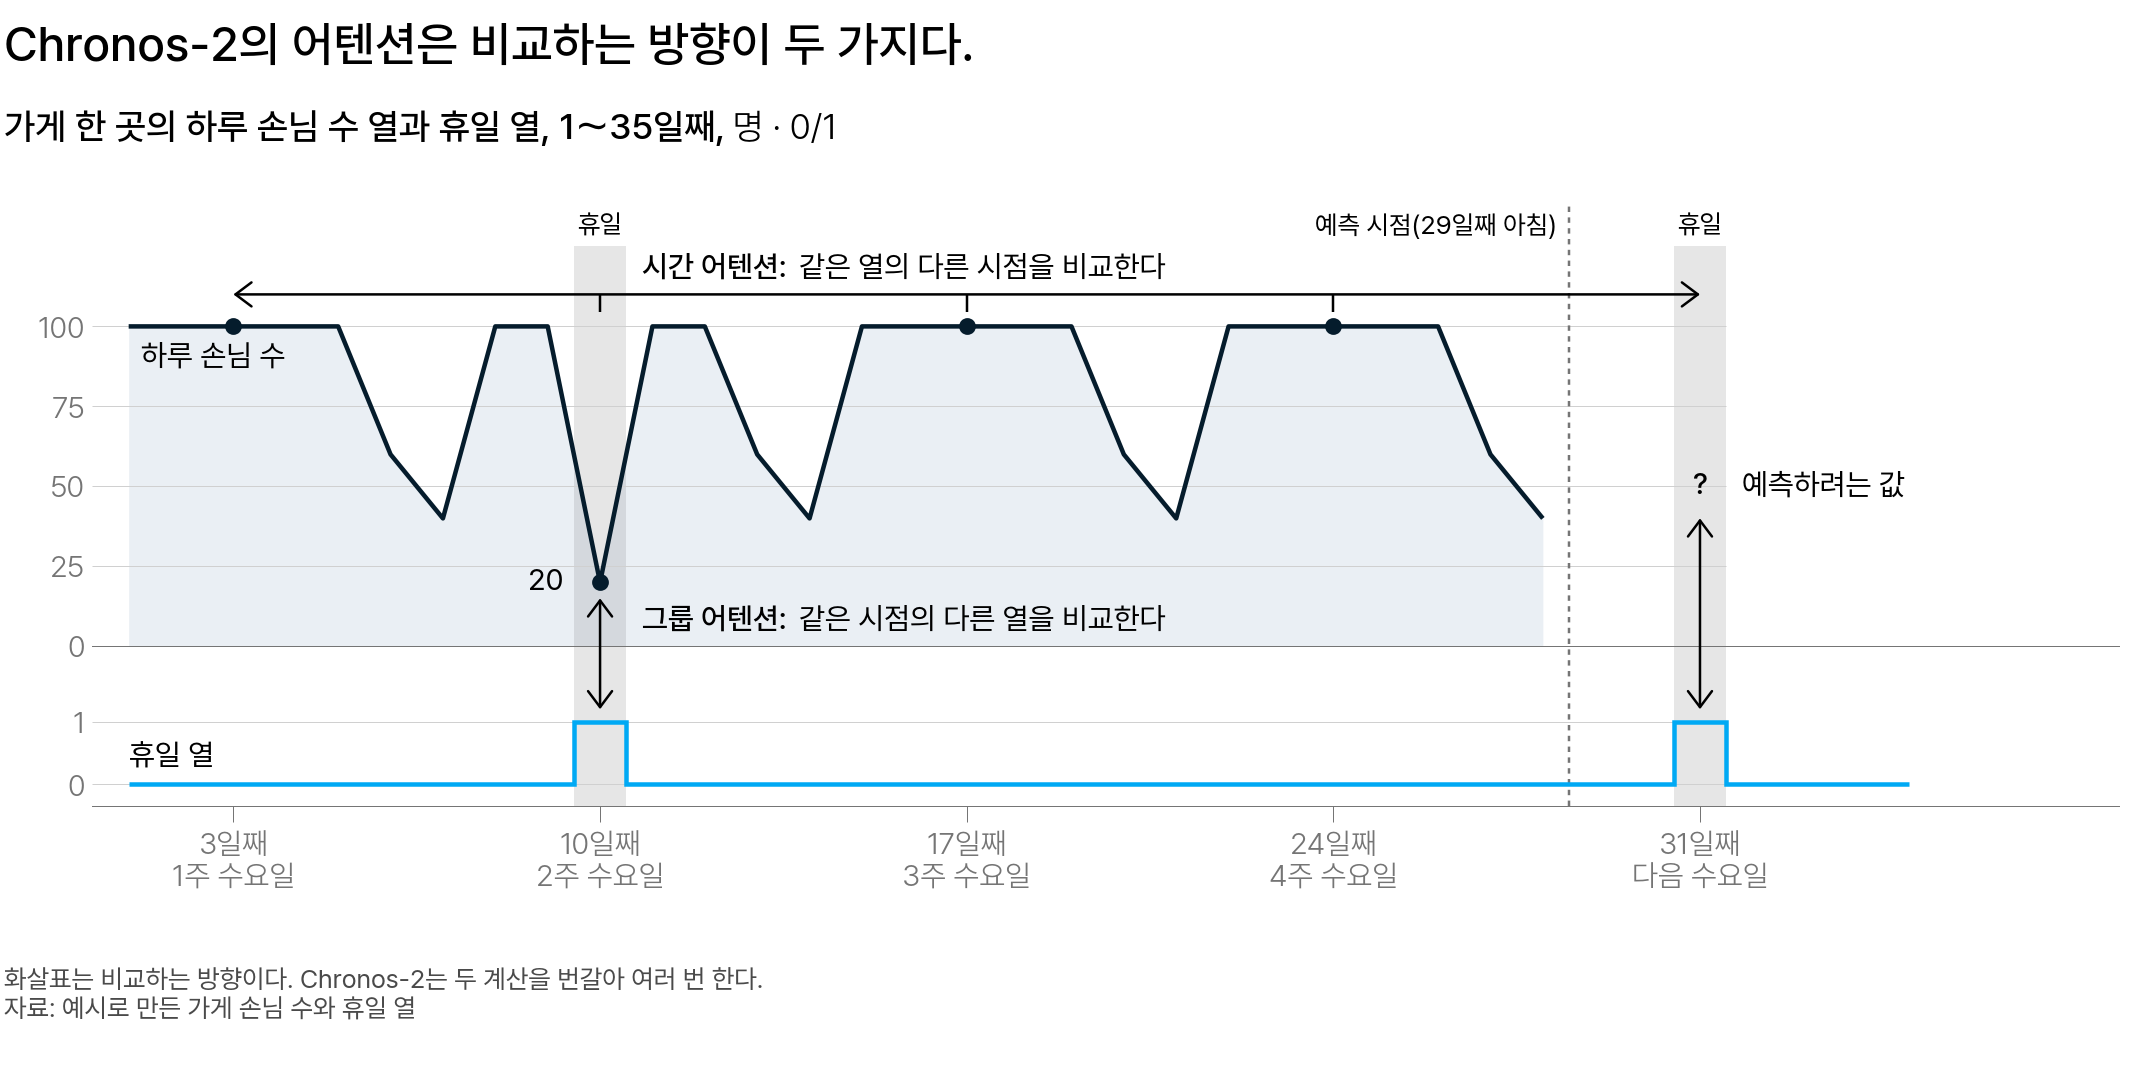

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로 화살표는 손님 수 열에서 다음 수요일과 지난 네 수요일을 잇는다. 세로 화살표 둘은 2주 수요일과 다음 수요일에서 손님 수 열과 휴일 열을 잇는다</em></p>

**두 어텐션을 계산하는 순서**

Chronos-2 의 한 층은 두 계산을 차례로 합니다. 먼저 열마다 시간 어텐션을 계산하고, 이어서 같은 시점의 열끼리 그룹 어텐션을 계산합니다.

다음 수요일에는 손님 수가 비어 있지만, 같은 시점의 휴일 값 1 은 있습니다. 그룹 어텐션으로 이 값이 손님 수 쪽에 반영됩니다.

2주 수요일에서도 손님 수 20명 쪽에 그날의 휴일 값 1 이 반영됩니다.

Chronos-2 는 이 층을 여러 번 되풀이합니다. 2주 수요일과 다음 수요일은 둘 다 휴일 값 1 이 반영된 시점이라, 다음 층에서 두 시점을 닮은 시점으로 비교할 수 있습니다.

따라서 2주 수요일의 20명이 다음 수요일의 예측에 반영될 수 있습니다.

반면 결제 건수 같은 과거 공변량은 다음 주의 값이 비어 있습니다. 그래서 과거 구간에서만 쓰이고, 다음 주에는 반영할 값이 없습니다.

두 어텐션을 표 하나로 정리합니다.

| 어텐션 | 비교 방향 | 하는 일 |
|---|---|---|
| 시간 어텐션 | 같은 열의 다른 시점끼리 | 닮은 과거 구간의 값을 반영한다 |
| 그룹 어텐션 | 같은 시점의 같은 그룹 열끼리 | 공변량의 값을 예측하려는 값에 반영한다 |

**가중치를 고치지 않는데 휴일에 손님이 줄어든다는 정보는 어디서 얻을까요?** 두 어텐션이 비교하는 값, 곧 입력한 값에서 얻습니다.

휴일에 손님이 20명이었다는 것은 과거 표에, 다음 수요일이 휴일이라는 것은 미래 입력에 있습니다.

모델 가중치에는 함께 입력한 열을 예측에 쓰는 방법만 있습니다. Chronos-2 는 사전학습 때 컴퓨터로 만든 합성 자료로 이 방법을 학습했습니다.

즉, 휴일에 손님이 얼마나 줄어드는지는 **과거 표의 휴일 값과 그날의 손님 수**에서 얻습니다.

그래서 과거 표에 휴일이 한 번은 있어야 합니다. 과거 표가 짧으면 그 안에 휴일이 하루도 없을 수 있습니다. 따라서 휴일 열을 추가하기 전에, 과거 표에 휴일 값이 1 인 날이 있는지 확인합니다.

<details class="lms-extra"><summary>더 깊이 — Chronos-2 구조 그림 읽기</summary>

Chronos-2 기술 보고서의 구조 그림입니다. 위쪽은 계산 차례이고, 아래쪽은 위 단계의 안을 자세히 그린 것입니다.

<img src="https://arxiv.org/html/2510.15821v1/x1.png" alt="Chronos-2 구조 그림. 입력의 예측하려는 계열과 Known Covariate, 토큰화, 시간 어텐션과 그룹 어텐션, 분위수 출력층" width="640" height="264"/>
<p align="center"><em>▲ Chronos-2 의 구조. 왼쪽 INPUT 에서 KNOWN COVARIATE 의 점선은 FUTURE 구간까지 이어지고, TARGET(S) 는 HISTORY 에서 끝난다 (출처: Ansari 외, Chronos-2: From Univariate to Universal Forecasting, arXiv:2510.15821 Figure 1)</em></p>

먼저 왼쪽 INPUT 에 있는 이름입니다.

| 그림에 적힌 이름 | 뜻 | 가게 예시 | 서울 지하철 |
|---|---|---|---|
| TARGET(S) #1 | 예측하려는 계열 | 가게 A 의 손님 수 | 한 역의 승차 인원 |
| KNOWN COVARIATE #1 | 미래 공변량 | 가게 A 의 휴일 열 | 그 역의 공휴일 열 |
| HISTORY · FUTURE | 과거와 예측할 기간 | 28일과 다음 주 7일 | 512일과 예측할 7일 |
| 같은 색의 계열 | 한 그룹 | 가게 A 의 두 열 | 한 역의 두 열 |

다음으로 위쪽의 상자를 왼쪽부터 읽습니다. 표에 없는 이름은 Chronos-2 의 계산 차례를 배울 때 다뤘습니다.

| 상자의 이름 | 하는 일 |
|---|---|
| ROBUST SCALING | 계열마다 과거 구간의 평균과 표준편차로 값을 바꾼다. 휴일 열도 바뀐 값으로 입력된다 |
| TOKENIZATION | 계열마다 16일 패치로 나눈다 |
| TIME ATTENTION | 같은 계열의 다른 패치를 비교한다(attention along time axis) |
| GROUP ATTENTION | 같은 패치 번호에서 같은 그룹의 다른 계열 값을 반영한다(attention within groups) |
| x N | 시간 어텐션 다음에 그룹 어텐션을 계산하는 층을 여러 번 지난다 |

예측할 7일은 16일 패치 하나의 앞 7일로 입력되고, 남는 9일은 없는 값으로 표시합니다.

이 패치에 예측하려는 값은 비어 있고, 휴일 값 7개는 있습니다. 가게 예시라면 0 · 0 · 1 · 0 · 0 · 0 · 0 입니다.

그룹 어텐션을 지나도 예측하려는 값과 휴일 열은 따로 있는 계열입니다. 계열마다 패치가 따로 있고, 같은 구간의 패치끼리 값을 반영합니다.

모델 안에서는 휴일 열 쪽의 출력도 계산되지만, 예측으로 쓰는 것은 손님 수 쪽의 출력뿐입니다.

</details>

### 공휴일 정보를 입력하면 예측이 어떻게 달라지는가 [필수]

가게 예시에서 다음 수요일이 휴일일 때, 직접 계산한 예측값은 이렇게 달라집니다.

| 입력 | 다음 수요일 예측값 | 실제 20명과의 차이 |
|---|---:|---:|
| 과거 손님 수만 | 93.8명 | 73.8명 |
| 과거 손님 수와 휴일 열 | 54.3명 | 34.3명 |

휴일 열을 더하자 예측값이 93.8명에서 54.3명으로 낮아졌습니다. 실제 20명보다는 높지만, 오차는 처음의 절반 아래로 줄었습니다.

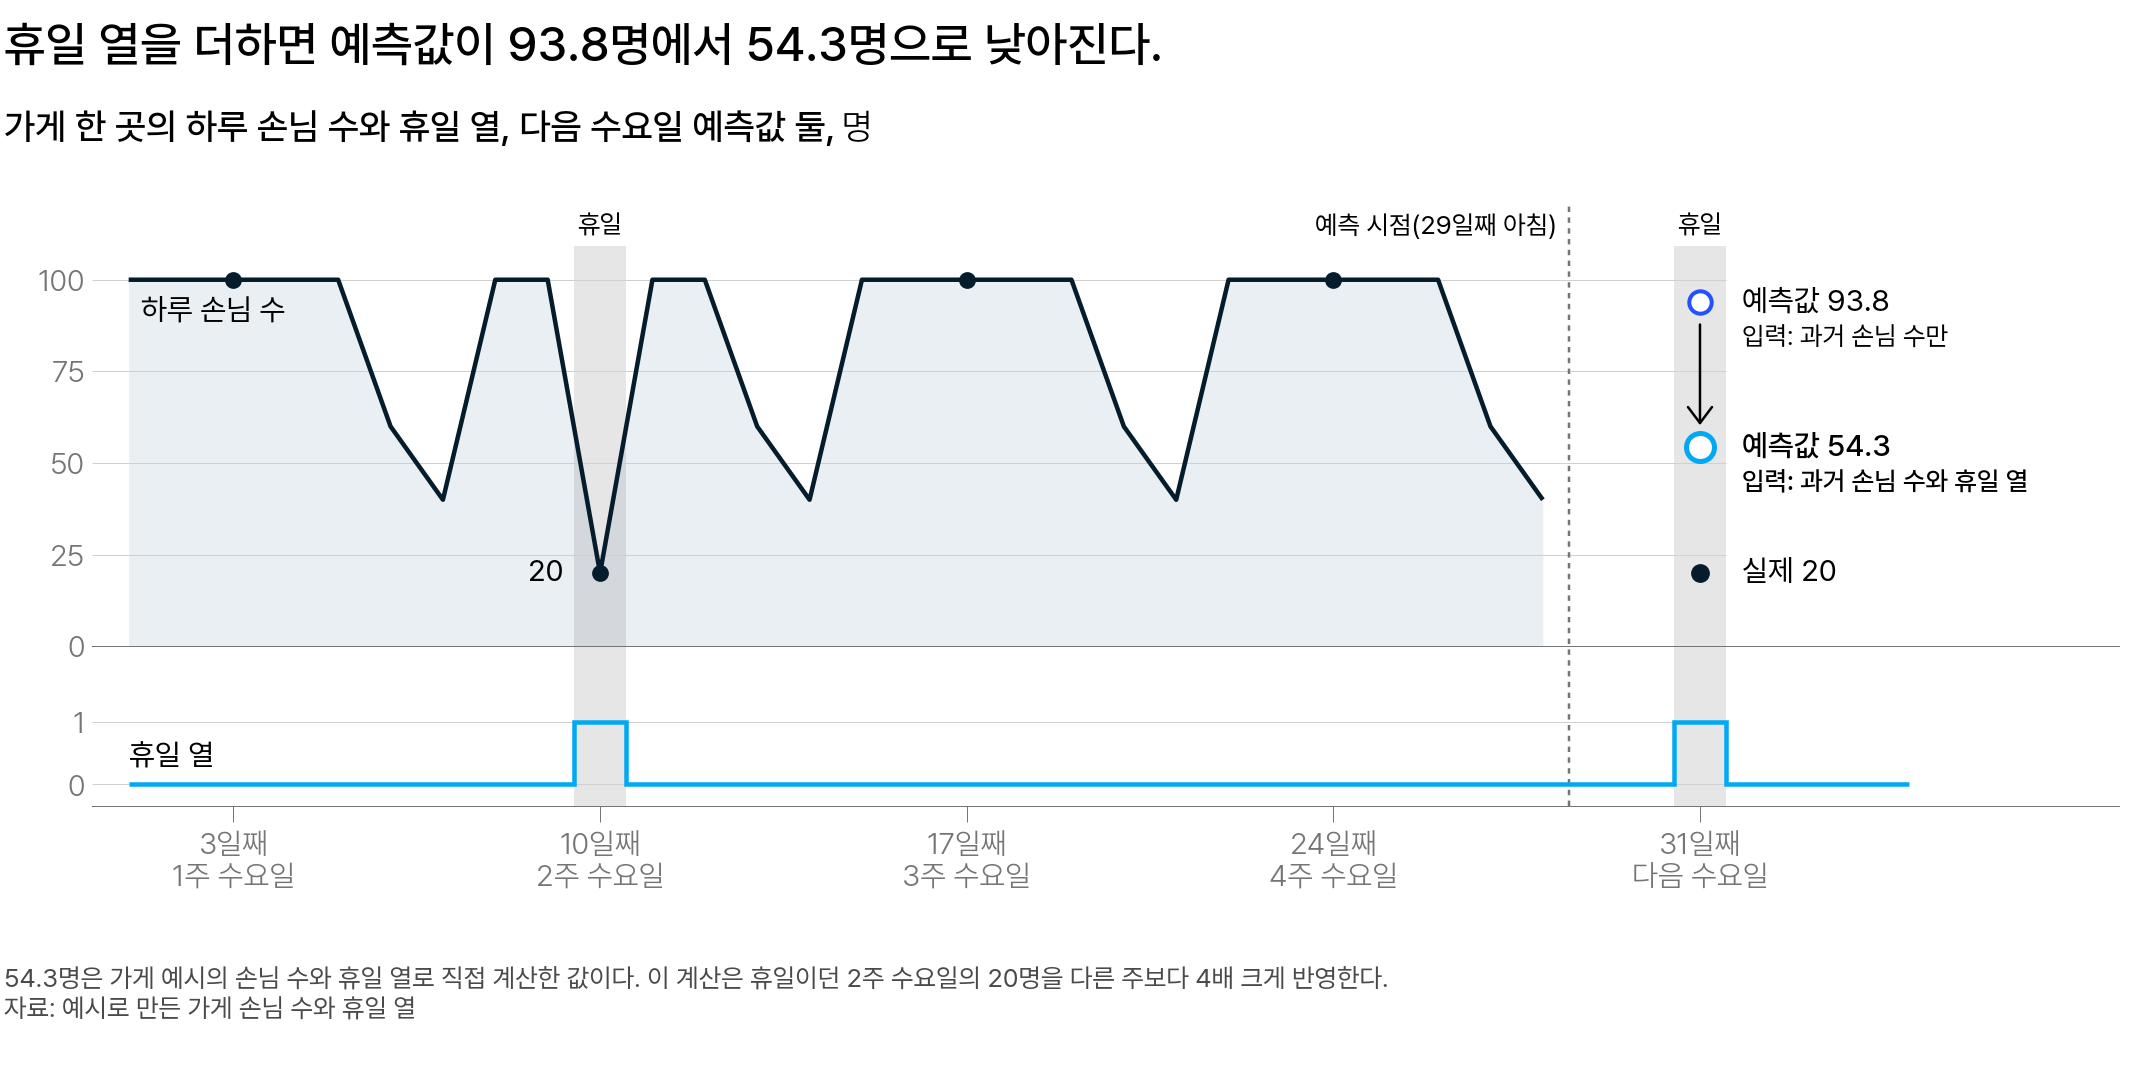

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 휴일 열을 더한 예측값 54.3명은 과거 손님 수만 입력한 93.8명보다 실제 20명에 가깝다</em></p>

54.3명은 Chronos-2 가 계산한 값이 아닙니다. 이 계산으로는 휴일 여부가 닮은 주의 손님 수를 더 크게 반영한다는 원리만 확인합니다. Chronos-2 는 한 주 대신 16일 패치 단위로 비교하고, 닮은 정도를 모델 가중치로 계산합니다.

계산 방법은 93.8명과 같은 가중 평균입니다. 다른 점은 닮은 정도를 손님 수 대신 휴일 여부로 계산한다는 것입니다.

93.8명을 계산할 때는 손님 수가 닮은 주를 더 크게 반영했습니다. 그래서 수요일이 20명이던 2주가 1, 나머지 세 주가 4 의 비였습니다.

그런데 휴일 여부로 비교하면 결과가 반대입니다. 다음 주와 휴일 여부가 7일 모두 같은 주는 2주뿐이고, 나머지 세 주는 수요일 하루가 다릅니다.

따라서 이번에는 2주를 4, 나머지 세 주를 1 의 비로 반영합니다.

$$
(1 \times 100 + 4 \times 20 + 1 \times 100 + 1 \times 100) \div 7 = 380 \div 7 \approx 54.3 \text{ 명}
$$

나누는 수 7 은 네 주의 비를 모두 더한 값입니다.

예측값이 20명까지 낮아지지 않은 까닭도 이 식에 있습니다. 휴일이 없던 세 주의 100명이 7분의 1 씩 반영되기 때문입니다.

아래 셀은 이 계산을 코드로 옮긴 것입니다. 출력의 마지막 값이 다음 수요일 예측값입니다. 비가 4 와 1 이 되는 계산은 셀 아래 접힌 상자에 있습니다.

`next_wed_holiday = 1` 을 `0` 으로 바꿔 다시 실행하면 예측값이 달라집니다. 먼저 예상한 뒤 실행해 확인합니다.

In [ ]:
# 가게 네 주: 다음 주의 휴일 값을 바꾸면 가중치와 예측값이 달라진다(유사도가 1 높을 때마다 비를 2배로)
import numpy as np

next_wed_holiday = 1                                   # 다음 수요일이 휴일이면 1, 아니면 0. 0 으로 바꿔 다시 실행해 봅니다
wed_guests = np.array([100, 20, 100, 100])             # 1～4주 수요일의 손님 수(명)
hol_past = np.zeros((4, 7), dtype=int)                 # 과거 표의 휴일 열: 네 주 × 월～일
hol_past[1, 2] = 1                                     # 2주 수요일만 휴일
hol_next = np.zeros(7, dtype=int)                      # 미래 입력의 휴일 열: 다음 주 7일
hol_next[2] = next_wed_holiday
sim_hol = np.where(hol_past == hol_next, 1, -1).sum(axis=1)   # 요일마다 휴일 값이 같으면 +1, 다르면 -1 로 계산해 더한 유사도
att_w = 2.0 ** sim_hol / (2.0 ** sim_hol).sum()               # 합이 1 인 비율 = 어텐션 가중치
print("유사도", sim_hol, "→ 가중치", att_w.round(2), "→ 다음 수요일 예측값", round(float(att_w @ wed_guests), 1))

`0` 으로 바꾸면 예측값은 93.8명입니다. 휴일 열을 더하지 않았을 때와 같은 값입니다.

다음 주에 휴일이 없으면 2주만 다음 주와 휴일 여부가 다릅니다. 그래서 2주가 1, 나머지 세 주가 4 의 비가 되어 처음의 계산과 같아집니다.

두 실행에서 과거 표는 같고, 달라진 것은 미래 입력의 값 하나입니다.

<details class="lms-extra"><summary>자세히 — 54.3명의 계산</summary>

위 셀의 출력은 유사도, 가중치, 예측값 차례입니다. 세 값을 같은 차례로 계산합니다.

**유사도**

주마다 다음 주와 휴일 여부(휴일이면 1, 아니면 0)를 요일별로 비교합니다. 같으면 +1, 다르면 −1 로 계산합니다.

1주와 다음 주를 비교하면 이렇습니다.

| 요일 | 1주 | 다음 주 | 계산한 값 |
|---|:-:|:-:|---:|
| 월 | 0 | 0 | +1 |
| 화 | 0 | 0 | +1 |
| 수 | 0 | 1 | −1 |
| 목 | 0 | 0 | +1 |
| 금 | 0 | 0 | +1 |
| 토 | 0 | 0 | +1 |
| 일 | 0 | 0 | +1 |

계산한 값 7개를 더하면 +1 이 여섯, −1 이 하나라 6 − 1 = 5 입니다. 이 값이 1주의 유사도입니다.

나머지 세 주도 같은 방법으로 계산합니다.

| 주 | 다음 주와 휴일 여부가 같은 날 | 다른 날 | 더한 값(유사도) |
|---|---:|---:|---:|
| 1주 | 6 | 1(수요일) | 6 − 1 = 5 |
| 2주 | 7 | 0 | 7 − 0 = 7 |
| 3주 | 6 | 1(수요일) | 6 − 1 = 5 |
| 4주 | 6 | 1(수요일) | 6 − 1 = 5 |

2주는 수요일이 휴일인 것까지 다음 주와 같아, 7일 모두 +1 입니다.

**가중치**

유사도를 가중치로 바꾸는 방법은 Chronos-2 의 어텐션을 배울 때와 같습니다. 유사도가 1 높을 때마다 가중치의 비를 2배로 합니다.

2주는 다른 주보다 유사도가 2 높아, 비가 다른 주의 2 × 2 = 4배입니다.

| 주 | 유사도 | 가중치의 비 | 가중치(비 ÷ 7) |
|---|---:|---:|---:|
| 1주 · 3주 · 4주 | 5 | 1 씩 | 1 ÷ 7 ≈ 0.14 씩 |
| 2주(수요일 휴일) | 7 | 2 × 2 = 4 | 4 ÷ 7 ≈ 0.57 |
| 네 주의 비를 모두 더한 값 | | 1 + 4 + 1 + 1 = 7 | |

여기서 가중치는 입력에서 계산하는 어텐션 가중치입니다. 고치지 않는 모델 가중치와는 다른 값입니다.

**예측값**

주마다 수요일 손님 수에 그 주의 비를 곱해 더하고, 네 주의 비를 모두 더한 값 7 로 나눕니다. 본문의 식이 이 계산입니다.

과거 손님 수로 구한 가중치와 함께 보면, 2주의 가중치가 0.08 에서 0.57 로 커졌습니다.

| 주 | 수요일 손님 수 | 과거 손님 수로 구한 가중치 | 휴일 여부로 구한 가중치 |
|---|---:|---:|---:|
| 1주 | 100명 | 0.31 | 0.14 |
| 2주(수요일 휴일) | 20명 | 0.08 | 0.57 |
| 3주 | 100명 | 0.31 | 0.14 |
| 4주 | 100명 | 0.31 | 0.14 |
| 다음 수요일 예측값 | | 93.8명 | 54.3명 |

가중치는 소수 둘째 자리로 반올림한 값입니다. 위 셀에서 `next_wed_holiday` 를 `0` 으로 바꾸면 가운데 열의 가중치가 출력됩니다.

**2배 대신 실제 소프트맥스(약 2.72배)로 계산한 값**

위 계산은 유사도가 1 높을 때마다 비를 2배로 했습니다. 실제 소프트맥스는 자연상수 e, 곧 약 2.72배로 합니다.

2주는 다른 주보다 유사도가 2 높습니다. 그래서 2주의 비는 e 를 두 번 곱한 값, 곧 약 7.39 입니다.

네 주의 비를 모두 더한 값 10.39 로 나누면 가중치입니다.

$$
\begin{aligned}
\text{네 주의 비:}\quad & 1 : 7.39 : 1 : 1 \quad (\text{합 } 10.39) \\
\text{가중치:}\quad & 1 \div 10.39 \approx 0.10, \qquad 7.39 \div 10.39 \approx 0.71
\end{aligned}
$$

네 수요일의 손님 수에 비를 곱해 더하고, 같은 값 10.39 로 나눕니다.

$$
(1 \times 100 + 7.39 \times 20 + 1 \times 100 + 1 \times 100) \div 10.39 = 447.8 \div 10.39 \approx 43.1 \text{ 명}
$$

2배로 계산한 54.3명보다 실제 20명에 더 가깝습니다.

어느 배수를 써도 휴일이던 2주의 가중치가 가장 큽니다.

</details>

**공휴일 열의 한계**

휴일 열은 값이 0 과 1 뿐입니다. 그래서 하루 쉬는 휴일과 명절이 같은 1 입니다. 서울 지하철의 공휴일 열에서도 설 연휴와 광복절이 모두 1 입니다.

그런데 손님이 줄어드는 크기는 휴일마다 다를 수 있습니다. 이번에는 3주 수요일도 휴일인 가게를 봅니다.

| 수요일 | 1주 | 2주(명절) | 3주(하루 쉬는 휴일) | 4주 | 다음 주 |
|---|---:|---:|---:|---:|---:|
| 손님 수(명) | 100 | 20 | 60 | 100 | ? |
| 휴일 열 | 0 | 1 | 1 | 0 | 1 |

손님 수는 20명과 60명으로 다르지만, 휴일 열의 값은 두 수요일 모두 1 입니다.

그래서 다음 수요일이 명절이어도 하루 쉬는 휴일이어도 같은 값을 예측합니다. 과거의 두 휴일 20명과 60명이 같은 비로 반영되어, 어느 휴일에도 맞지 않는 값이 됩니다.

> 휴일 열의 값 1 에는 휴일이라는 사실만 있고, 손님이 얼마나 줄어드는 휴일인지는 없습니다.

서울 지하철에서는 설 연휴가 이 경우입니다. 그 예측은 「3. 서울 지하철 100개 역 결과」에서 확인합니다.

또 휴일 열을 더하면 휴일이 없는 주의 예측도 달라질 수 있습니다. 과거의 휴일 값이 함께 입력되기 때문입니다.

가게 예시의 계산에서는 다음 주에 휴일이 없으면 예측값이 93.8명 그대로였습니다. 그러나 Chronos-2 의 계산은 이 계산과 달라, 같은 결과를 기대할 수 없습니다. 실제 결과는 「3. 서울 지하철 100개 역 결과」의 공휴일이 없는 주에서 확인합니다.

평균 하나로 채점하면 휴일이 있는 주의 변화와 없는 주의 변화가 한 값에 합쳐집니다.

따라서 휴일 열을 더한 뒤에는 **공휴일이 있는 주와 없는 주를 나눠서** 다시 채점합니다.

<details class="lms-extra"><summary>더 깊이 — 휴일의 종류를 구별하는 방법과 논문의 사례</summary>

**휴일의 종류를 구별하는 방법**

Prophet 은 휴일마다 계수를 따로 학습했습니다. 그래서 명절과 하루 쉬는 휴일의 효과가 서로 다른 값이었습니다.

Chronos-2 에서는 휴일의 종류를 범주형 공변량으로 입력할 수 있습니다. 범주형 공변량은 값이 설날 · 광복절 같은 이름인 열입니다.

명절 열과 나머지 휴일 열을 따로 포함하는 방법도 있습니다. 그러면 두 휴일이 서로 다른 열의 1 로 전달됩니다.

이 과정에서는 두 방법을 채점하지 않았습니다. 해 보려면 공휴일이 있는 주와 없는 주를 나눠서 다시 채점해, 휴일 열 하나만 포함한 예측과 비교합니다.

**논문의 사례: 매장 매출과 전기 가격**

Chronos-2 는 사전학습에 컴퓨터로 만든 합성 자료를 썼습니다. 합성 자료에서는 여러 열이 서로 관계를 갖도록 만들고, 그 가운데 일부 열을 미래 공변량으로 정했습니다.

그래서 같은 방법이 휴일 여부가 아닌 열에도 쓰입니다. 예를 들어 매장 매출에는 판촉 일정을, 전기 가격에는 전력 수요 예보를 함께 전달할 수 있습니다.

Chronos-2 기술 보고서에는 이 두 과제에서 공변량을 입력하자 예측이 달라진 사례가 있습니다.

<img src="https://arxiv.org/html/2510.15821v1/x12.png" alt="Rossmann 매출을 공변량 없이와 공변량과 함께 예측한 Chronos-2 결과, 아래는 Open · Promo · SchoolHoliday · StateHoliday · Customers 계열" width="640" height="448"/>
<p align="center"><em>▲ Chronos-2 로 독일 드러그스토어 체인 Rossmann 의 주간 매출을 예측한 그림. 맨 위는 공변량 없이, 둘째는 공변량과 함께 얻은 예측이다. 아래 다섯 계열이 공변량이고, 세로 점선이 예측 시작이다 (출처: Ansari 외, arXiv:2510.15821 Figure 7)</em></p>

| 그림의 열 | 세로 점선 뒤에도 값이 있는가 | 종류 |
|---|---|---|
| `Open` · `Promo` · `SchoolHoliday` · `StateHoliday` | 있다(영업 계획 · 판촉 계획 · 달력) | 미래 공변량 |
| `Customers` | 없다(그 주가 지나야 안다) | 과거 공변량 |

공변량 없이 얻은 맨 위 예측은 거의 평평합니다. 공변량과 함께 얻은 둘째 예측은 매출의 오르내림을 따라갑니다.

손님 수 `Customers` 는 가게 예시의 결제 건수처럼 예측 시작에서 끝나는 과거 공변량입니다.

보고서는 공변량의 효과가 가장 큰 과제를 골라 보였다고 밝힙니다. 공변량이 언제나 도움이 된다는 뜻은 아닙니다.

아래 표는 그림에 적힌 이름을 위에서 아래로 옮긴 것입니다.

| 그림에 적힌 이름 | 뜻 |
|---|---|
| Sales | 예측하려는 값. 가게 하나의 주간 매출 |
| Forecast (Univariate) | 공변량 없이 얻은 예측 |
| Forecast (ICL) | 공변량과 함께 얻은 예측. 모델 가중치는 그대로다 |
| Open · Promo | 영업과 판촉을 주 단위로 모은 값 |
| SchoolHoliday · StateHoliday | 방학과 공휴일을 주 단위로 모은 값 |
| Customers | 손님 수를 주 단위로 모은 값 |
| 세로 점선 | 예측 시작 |
| 분홍 영역 | 80% 예측 구간 |

`Open` 의 값은 0 과 1 사이의 소수입니다. 하루의 1 과 0 을 한 주로 모은 값이기 때문입니다.

아래 다섯 계열 가운데 넷은 점선 뒤까지 이어지고, `Customers` 만 점선에서 끝납니다.

아래는 같은 보고서의 전기 가격 그림입니다.

<img src="https://arxiv.org/html/2510.15821v1/x11.png" alt="독일 전기 가격을 공변량 없이와 공변량과 함께 예측한 Chronos-2 결과, 아래는 Ampirion Load 와 Solar + Wind 계열" width="640" height="256"/>
<p align="center"><em>▲ Chronos-2 로 독일 전기 가격을 예측한 그림. 맨 위는 공변량 없이, 둘째는 전력 수요(Ampirion Load)와 태양광 · 풍력 발전량(Solar + Wind)을 함께 입력한 예측이다 (출처: Ansari 외, arXiv:2510.15821 Figure 6)</em></p>

전기 가격 그림의 두 공변량은 전력 수요와 발전량의 하루 앞 예보입니다.

예보라서 미래 공변량입니다. 가게 예시의 기온 예보와 같은 종류입니다.

</details>

<div class="lms-summary">

**정리**

다음 주의 휴일 값은 미래 입력 `future_df` 로 전달하고, 예측하려는 값은 미래 입력에 포함하지 않습니다. Chronos-2 는 열마다 따로 패치로 나눕니다. 그런 다음 시간 어텐션으로 같은 열의 다른 시점을, 그룹 어텐션으로 같은 시점의 다른 열을 비교합니다.

**할 일**

- 과거 표에 휴일이 있는지 확인합니다
- 값이 0 과 1 뿐인 열로는 휴일의 종류가 구별되지 않으므로, 명절의 예측은 따로 확인합니다
- 휴일 열을 더한 뒤에는 휴일이 없는 주도 다시 채점합니다

휴일 열은 휴일이 어느 날인지만 전달하고, 손님이 얼마나 줄어드는지는 과거 표의 값에서 얻습니다.

</div>

## 3. 서울 지하철 100개 역 결과

공휴일 열을 입력한 Chronos-2 를 모든 주의 역별 인력 예측에 써도 될까요?

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Seoul_subway_linemap_ko.svg" alt="서울 지하철 노선도" width="320" height="364"/>
<p align="center"><em>▲ 서울 지하철 노선도. 이 과정에서 예측하는 역은 지금까지와 같은 100개 역이고, 노선 13개에 있다 (출처: Wikimedia Commons, Seoul subway linemap ko.svg)</em></p>

### 강남역 설 연휴 주의 예측은 어떻게 달라졌는가 [필수]

가게 예시의 두 표를 서울 지하철 100개 역에 그대로 옮깁니다.

공휴일 열 `holiday` 는 holidays 라이브러리의 한국 달력에서 공휴일이면 1 인 열입니다. 주말인 공휴일도 1 입니다.

가게 예시의 예측 시점과 기간은 서울 지하철에서 이렇게 바뀝니다.

| 가게 예시 | 서울 지하철 100개 역 |
|---|---|
| 예측 시점(29일째 아침) | 예측 원점(수요일)의 아침 |
| 과거 28일 | 원점 전날까지 512일(컨텍스트) |
| 다음 주 7일 | 원점부터 7일(채점 7일) |

공휴일 열을 과거 표와 미래 입력에 모두 포함해 Chronos-2 로 예측합니다. 평가표에서는 이 예측을 **Chronos-2 + 공휴일** 이라고 부릅니다.

제로샷과 달라진 것은 공휴일 열 하나이고, 모델 가중치는 고치지 않습니다. 따라서 두 예측이 다르다면 공휴일 열 때문입니다.

과거 표는 역마다 512행이고, 미래 입력은 역마다 7행입니다.

강남역의 512일에는 공휴일이 26일 있어, 과거 표에 휴일이 있어야 한다는 조건을 만족합니다. 지난해 설날의 승차 인원 12,911명도 공휴일 값 1 과 함께 있습니다.

아래 셀은 강남역의 예측 원점 2026-02-11 에서 이 두 표를 작게 만듭니다. `future_df` 에 `target` 열이 없고, `holiday` 7개 가운데 마지막 2개(설 연휴 이틀)가 1 인 것을 확인합니다.

과거 표는 512행 가운데 마지막 3일만 만듭니다.

In [ ]:
# 강남역 원점 2026-02-11 에 Chronos-2 로 전달하는 두 표(df 는 마지막 3일만 보인다)
import pandas as pd

df = pd.DataFrame({"item_id": "2호선 강남",
                   "timestamp": pd.date_range("2026-02-08", periods=3),
                   "target": [36589, 91553, 95750],              # 승차(명)
                   "holiday": [0, 0, 0]})                         # 공휴일이면 1
future_df = pd.DataFrame({"item_id": "2호선 강남",
                          "timestamp": pd.date_range("2026-02-11", periods=7),
                          "holiday": [0, 0, 0, 0, 0, 1, 1]})     # 2월 16·17일 설 연휴
assert "target" not in future_df.columns and future_df["holiday"].sum() == 2
print("future_df 의 열:", list(future_df.columns), "(승차 target 열 없음)")
print("future_df 의 holiday 7일:", future_df["holiday"].tolist())
print("df 마지막 3일:")
print(df.to_string(index=False))

출력의 열 목록에 `target` 이 없습니다. 채점 7일의 승차 인원은 어느 표에도 없다는 뜻입니다.

자료 파일에서 표를 만들다 보면 예측 시점에 모르는 열이 함께 포함되기 쉽습니다. 따라서 예측하기 전에 `future_df` 의 열 목록부터 확인합니다.

> **[문제] Chronos-2 에 전달하는 `future_df` 에 있는 값은 무엇인가요?**
>
> 1. 채점 7일의 승차 인원(Chronos-2 가 예측하려는 값)
> 2. 원점 전날까지 512일의 공휴일 1 / 0
> 3. 채점 7일의 공휴일 1 / 0 (달력으로 정해져 있어 예측 원점의 아침에 이미 아는 값)

이제 강남역 설 연휴 주의 두 예측을 비교합니다. 하나는 과거 승차 인원만 입력한 제로샷이고, 다른 하나는 위 두 표로 예측한 Chronos-2 + 공휴일입니다.

**직접 해보기: 공휴일 열을 입력한 예측과 입력하지 않은 예측**

아래 위젯은 강남역의 예측과 실제 승차 인원을 그립니다. 파랑 선과 하늘색 선은 Chronos-2 예측의 0.5 분위수(예측값 하나로 쓰는 가운데 값)이고, 남색 선과 점은 실제 승차 인원입니다.

1. **해 보기.** `공휴일 열` 을 `입력함` 으로 바꿉니다.
2. **관찰.** 하늘색 예측선이 파랑 예측선보다 크게 낮은 날과 `미래 입력의 공휴일 열` 에서 값이 1 인 날을 비교합니다.
3. **확인 질문.** `예측한 주` 를 `공휴일이 없는 주(2025-12-10)` 로 바꾸고 다시 `입력함` 을 누르면, 예측선은 얼마나 달라질까요?

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/deep-time-series/holiday-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — 공휴일이 없는 주</summary>

예측선은 눈에 띄게 달라지지 않지만 같지는 않습니다. `두 예측의 차이가 가장 큰 날` 인 12월 13일(토)의 예측이 70,615명에서 67,052명으로 3,563명 낮아집니다. `7일 평균 오차` 는 1,453명에서 2,171명으로 커집니다. 공휴일이 없는 이 주에는 공휴일 열을 입력해도 오차가 줄지 않았습니다.

`입력함` 으로 바꾸면 예측할 7일의 공휴일 값과 함께 과거 512일의 공휴일 열도 Chronos-2 에 전달됩니다. 입력이 달라졌으므로, 7일의 공휴일 값이 모두 0 인 주의 예측도 조금 달라집니다.

100개 역에서도 그런지는 「공휴일이 있는 주와 없는 주의 평가 결과」에서 확인합니다.

</details>

위젯의 `7일 평균 오차` 는 예측과 실제의 차이를 7일 평균한 값이고, 단위는 명입니다. 평가표의 MASE 는 이 값을 역마다 정한 기준 오차로 나눈 값입니다.

`광복절이 있는 주(2025-08-13)` 에서는 하루 쉬는 공휴일의 예측을 같은 방법으로 확인할 수 있습니다.

아래 그림은 위젯의 `설 연휴가 있는 주(2026-02-11)` 를 수와 함께 옮긴 것입니다.

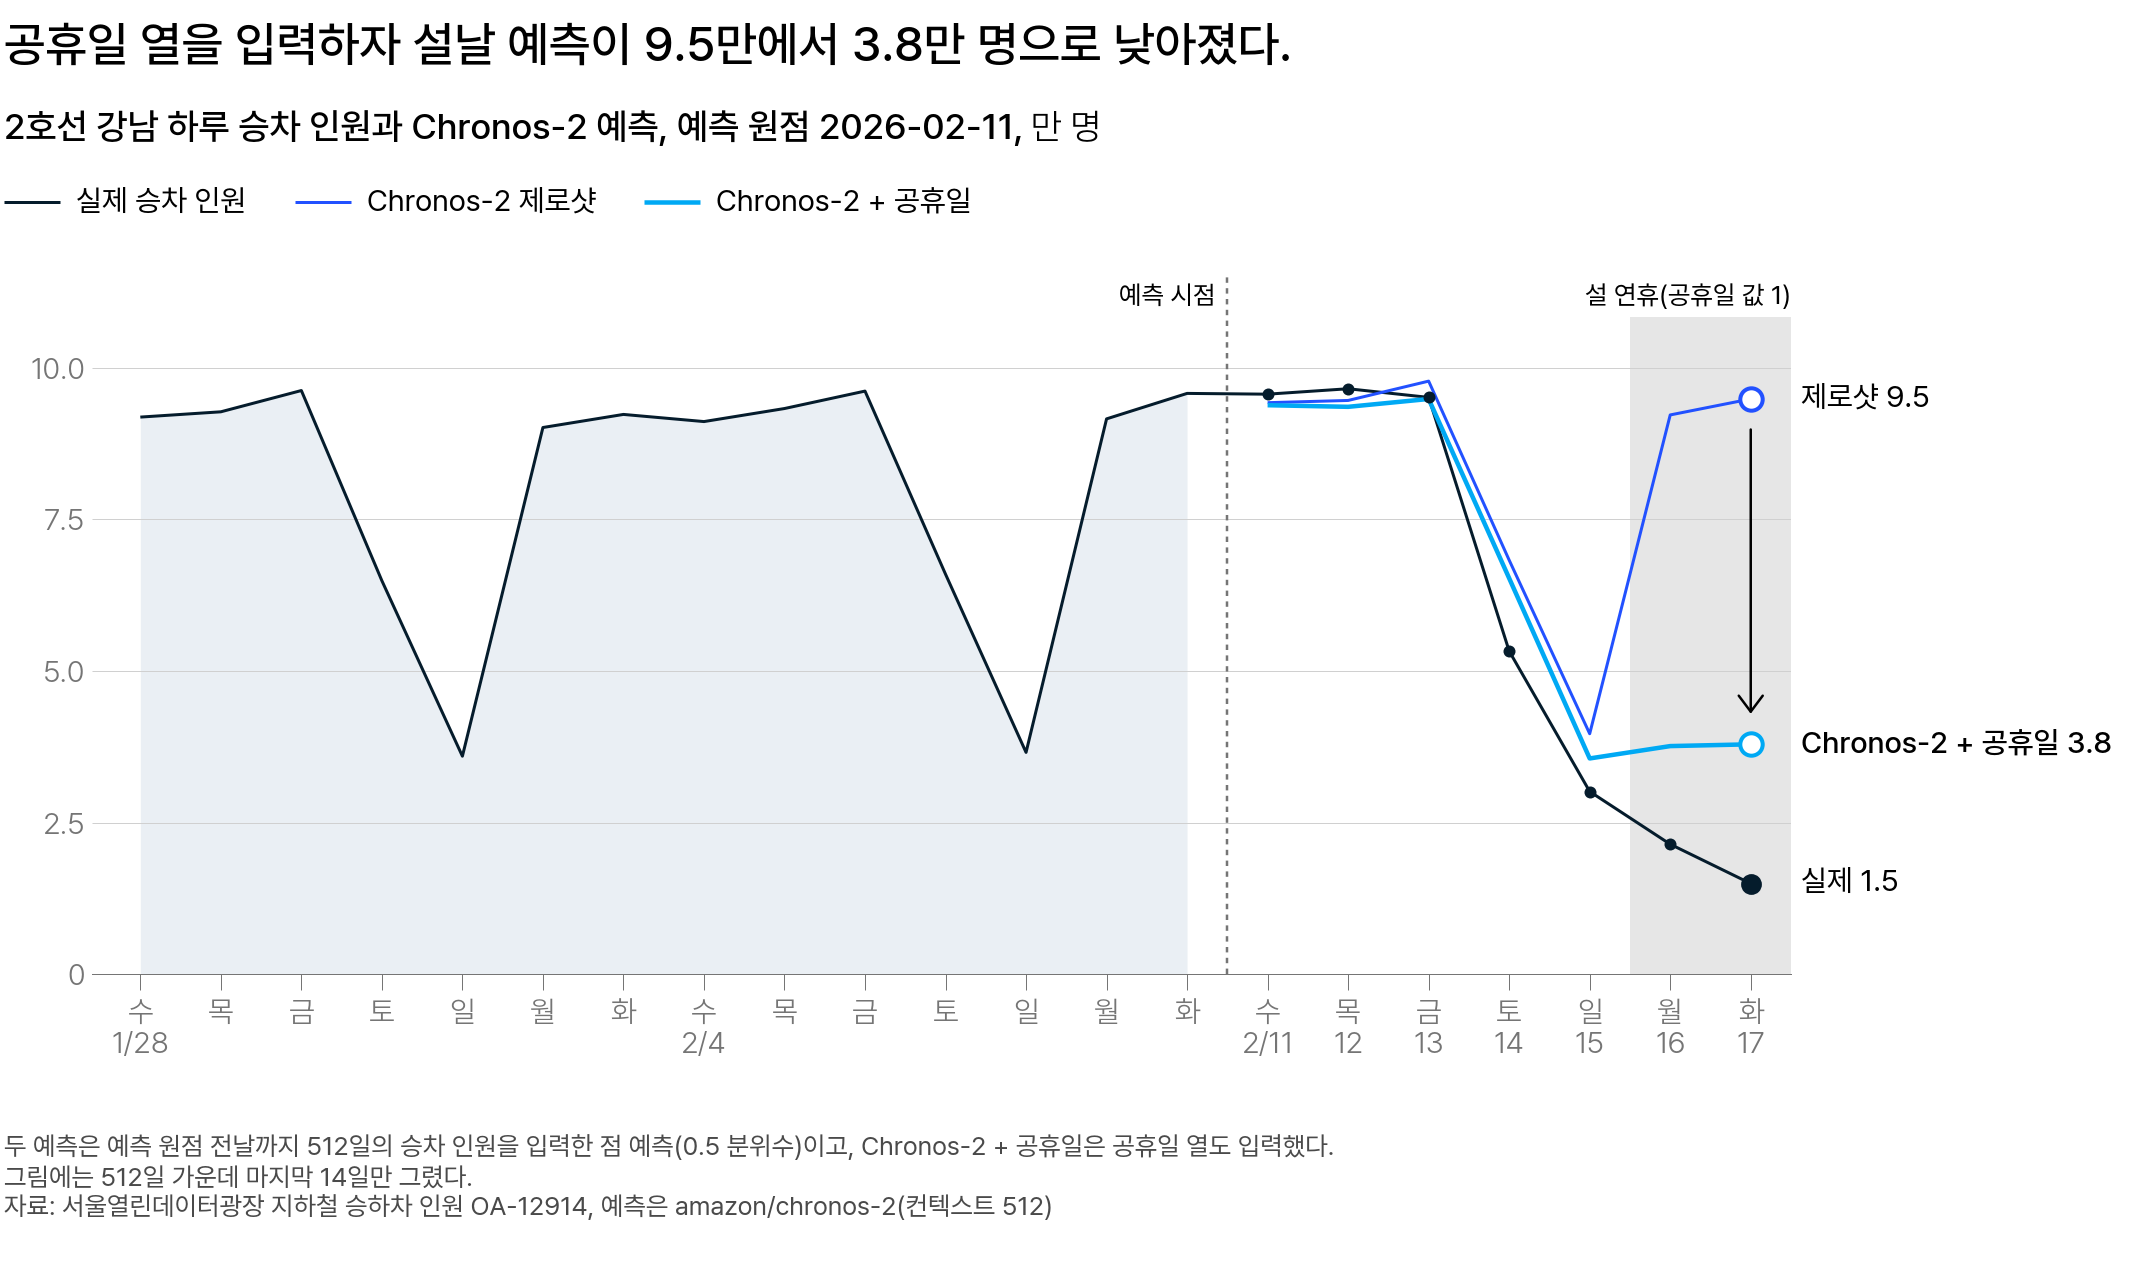

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 공휴일 값이 1 인 설 연휴 이틀에 두 예측이 크게 달라진다. 설날의 Chronos-2 + 공휴일 예측 3.8만 명도 실제 1.5만 명보다 높다</em></p>

먼저 공휴일 값이 1 인 이틀입니다. 제로샷은 이 이틀을 9만 명대로 예측했습니다. 1주 전 월요일과 화요일의 승차 인원과 비슷한 크기입니다.

공휴일 열을 입력하자 이틀의 예측이 약 3.8만 명으로 낮아졌습니다. 제로샷 예측의 절반에 못 미치는 값입니다.

다음은 공휴일 값이 0 인 2월 11～15일입니다. 이 5일은 두 예측이 가장 크게 다른 날에도 차이가 4,074명입니다.

다만 차이가 0 은 아닙니다. 공휴일 열을 함께 입력하면 공휴일 값이 0 인 날의 예측도 조금 달라집니다.

즉, 채점 7일의 공휴일 값을 입력하자 **그 값이 1 인 날의 예측만** 크게 낮아졌습니다. 다만 그 이틀도 예측이 실제보다 높습니다.

<details class="lms-extra"><summary>자세히 — 식으로 쓰면 입력에 더해진 것</summary>

Chronos-2 제로샷의 식에서 입력에 공휴일 값 $x$ 가 더해집니다.

$$
\hat y_{o}, \dots, \hat y_{o+6} = g_{\theta}(y_{o-512}, \dots, y_{o-1};\ x_{o-512}, \dots, x_{o+6})
$$

- $o$: 예측 원점
- $y$: 승차 인원(명), `target` 열
- $x$: 공휴일 값, `holiday` 열
- $g_{\theta}$: 가중치 $\theta$ 를 고치지 않은 Chronos-2

승차 인원은 512일만, 공휴일 값은 예측할 7일까지 519일을 입력한다는 뜻입니다.

원점 2026-02-11 의 강남역이면 $x_{o+5} = x_{o+6} = 1$ 입니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 원자료 세 행 · 지난해 설 연휴 · 설 연휴 앞 주말</summary>

원자료(서울열린데이터광장 OA-12914)의 한 행은 역 하나의 하루입니다.

| `사용일자` | `노선명` | `역명` | `승차총승객수` | `하차총승객수` | `등록일자` |
|---|---|---|---:|---:|---|
| 20260210 | 2호선 | 강남 | 95750 | 92132 | 20260213 |
| 20260210 | 2호선 | 잠실(송파구청) | 82306 | 80430 | 20260213 |
| 20260216 | 2호선 | 강남 | 21453 | 20944 | 20260219 |

공개 자료는 `사용일자` 의 3일 뒤에 등록됩니다.

이 과정의 채점은 예측 원점의 아침에 전날까지의 승차 인원을 이미 받았다고 가정합니다.

100개 역 표는 승차 인원만 모은 표이고, 하차 인원은 원자료에만 있습니다.

원점 2026-02-11 의 512일 입력에는 지난해 설 연휴가 있습니다.

| 날짜 | 달력 | 강남역 승차 인원 |
|---|---|---:|
| 2025-01-24(금) | 평일 | 97,037명 |
| 2025-01-27(월) | 임시공휴일 | 39,831명 |
| 2025-01-28(화) | 설날 전날 | 20,086명 |
| 2025-01-29(수) | 설날 | 12,911명 |
| 2025-01-30(목) | 설날 다음날 | 24,875명 |
| 2025-01-31(금) | 평일 | 78,486명 |

512일 입력에는 공휴일이 26일 있고, 공휴일 열에서는 26일이 모두 1 입니다.

**설 연휴 바로 앞의 주말**

2월 14 · 15일은 설 연휴 바로 앞의 주말입니다.

이 주말의 실제 승차 인원은 약 5.3만 · 3.0만 명으로, 평소 주말(약 6.5만 · 3.6만 명)보다 낮았습니다.

그런데 공휴일 값은 0 이라, 두 예측 모두 평소 주말에 가깝습니다. 달력의 공휴일이 아닌 날의 변화는 공휴일 열로 전달되지 않습니다.

</details>

### 공휴일이 있는 주와 없는 주의 평가 결과 [필수]

강남역 한 주에서 본 것을 100개 역, 예측 원점 5개로 넓힙니다.

평가 지표는 MASE 입니다.

- MASE 가 작을수록 예측이 실제에 가깝습니다.
- MASE 가 1 이면 계절 나이브가 평소 내던 오차만큼 틀린 것입니다.
- 평가표의 값은 역마다 계산한 MASE 의 100개 역 평균입니다.

**전체 결과**

| 방식 | 평균 MASE | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|---:|
| 계절 나이브 | 1.838 | 0.445 | 2.767 |
| 직전 7일 평균 | 2.984 | 1.935 | 3.684 |
| 글로벌 MLP(MSE 손실) | 1.848 | 0.739 | 2.587 |
| 글로벌 MLP(MAE 손실) | 1.774 | 0.359 | 2.717 |
| Chronos-2 제로샷 | 1.766 | 0.271 | 2.763 |
| **Chronos-2 + 공휴일** | **0.742** | **0.322** | **1.022** |

위 다섯 방식은 지금까지의 평가표이고, 마지막 방식은 같은 원점 5개를 다시 채점한 값입니다.

표에서 계절 나이브의 평균 MASE 는 1 이 아니라 1.838 입니다. MASE 의 기준은 예측 원점 전날까지 계절 나이브가 낸 오차이기 때문입니다. 채점한 주의 오차는 이 기준과 다를 수 있습니다.

공휴일 열을 입력하자 Chronos-2 의 원점 5개 평균 MASE 가 제로샷의 1.766 에서 0.742 로 낮아졌습니다.

하지만 평균 하나만 보고 모든 주에 쓰기로 정하지 않습니다. 평균만으로는 공휴일이 있는 주에서 낮아졌는지, 없는 주에서 낮아졌는지 알 수 없기 때문입니다.

그래서 원점 5개를 채점 7일에 평일 공휴일이 있는 세 주와 없는 두 주로 나눠서 비교합니다. 공휴일 있는 세 주는 광복절, 개천절과 추석, 설 연휴가 있는 주입니다.

**공휴일이 있는 주**

| 방식 | 공휴일 있는 세 주의 MASE |
|---|---:|
| 계절 나이브 | 2.767 |
| Chronos-2 제로샷 | 2.763 |
| Chronos-2 + 공휴일 | 1.022 |

공휴일 있는 세 주에서는 MASE 가 2.763 에서 1.022 로 낮아졌습니다. 1.022 는 계절 나이브가 평소 내던 오차와 거의 같은 크기입니다.

두 값의 차이 1.741 은 시드 범위 0.077 보다 큽니다.

시드 범위는 MLP(MSE 손실)를 시드만 바꿔 다시 학습했을 때 평균 MASE 가 달라진 범위입니다. 그래서 차이가 이보다 작으면 두 모델에 차이가 있다고 보지 않습니다.

역마다 비교해도 결과가 같습니다. 역 하나와 원점 하나에서 계산한 MASE 를 **역-원점 MASE** 라고 부릅니다.

역 100개와 원점 3개의 조합 300건 가운데 292건에서 이 값이 제로샷보다 낮습니다. 설 연휴가 있는 주도 100개 역 모두 MASE 가 낮아졌습니다.

처음에 본 평일 공휴일 6일의 예측도 실제에 가까워졌습니다. 100개 역의 예측을 모두 더한 값이 실제 승차 인원의 2.14배에서 1.10배로 낮아졌습니다.

따라서 공휴일이 있는 주에는 Chronos-2 + 공휴일을 씁니다.

<details class="lms-extra"><summary>자세히 — 공휴일 열을 과거 표에만 포함하면</summary>

공휴일 열을 과거 표 `df` 에만 포함하고 `future_df` 를 빼면, 공휴일 있는 세 주의 MASE 는 제로샷과 거의 같습니다.

| 공휴일 있는 세 주의 MASE | 값 | 출처 |
|---|---:|---|
| Chronos-2 제로샷 | 2.763 | 평가표의 값 |
| 공휴일 열을 과거 표에만 포함한 예측 | 2.756 | 같은 원점 5개를 다시 채점 |

두 값의 차이 0.007 은 시드 범위 0.077 보다 작아, 차이가 있다고 보지 않습니다.

거의 같은 까닭은 예측할 7일 가운데 어느 날이 공휴일인지가 전달되지 않기 때문입니다. 지난 공휴일의 값은 전달되지만, 그것만으로는 다음 주의 어느 날이 공휴일인지 알 수 없습니다.

즉, 예측할 7일의 공휴일 값은 `future_df` 로 전달해야 예측에 반영됩니다.

</details>

**공휴일이 없는 주**

| 방식 | 공휴일 없는 두 주의 MASE |
|---|---:|
| 계절 나이브 | 0.445 |
| Chronos-2 제로샷 | 0.271 |
| Chronos-2 + 공휴일 | 0.322 |

두 모델 모두 계절 나이브보다 낮고, 그 차이는 시드 범위 0.077 보다 큽니다.

그런데 Chronos-2 + 공휴일은 제로샷보다 0.051 높습니다. 이 차이는 시드 범위 0.077 보다 작습니다.

따라서 평균 MASE 만으로는 두 모델 가운데 어느 쪽이 더 낫다고 하지 않습니다. 평균으로 정할 수 없으므로 역마다 비교합니다.

> **[예측] 공휴일 없는 두 주는 채점 7일의 공휴일 열이 모두 0 입니다. 역 100개와 원점 2개의 조합은 200건입니다. 이 가운데 Chronos-2 + 공휴일의 MASE 가 제로샷보다 낮아진 것은 몇 건일까요?**
>
> 1. 거의 전부
> 2. 절반쯤
> 3. 절반보다 적게
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

셋째 보기가 맞습니다. 200건 가운데 52건에서만 낮아졌고, 148건에서는 높아졌습니다.

아래 그림은 이 200건을 원점마다 역 하나를 점 하나로 그린 것입니다.

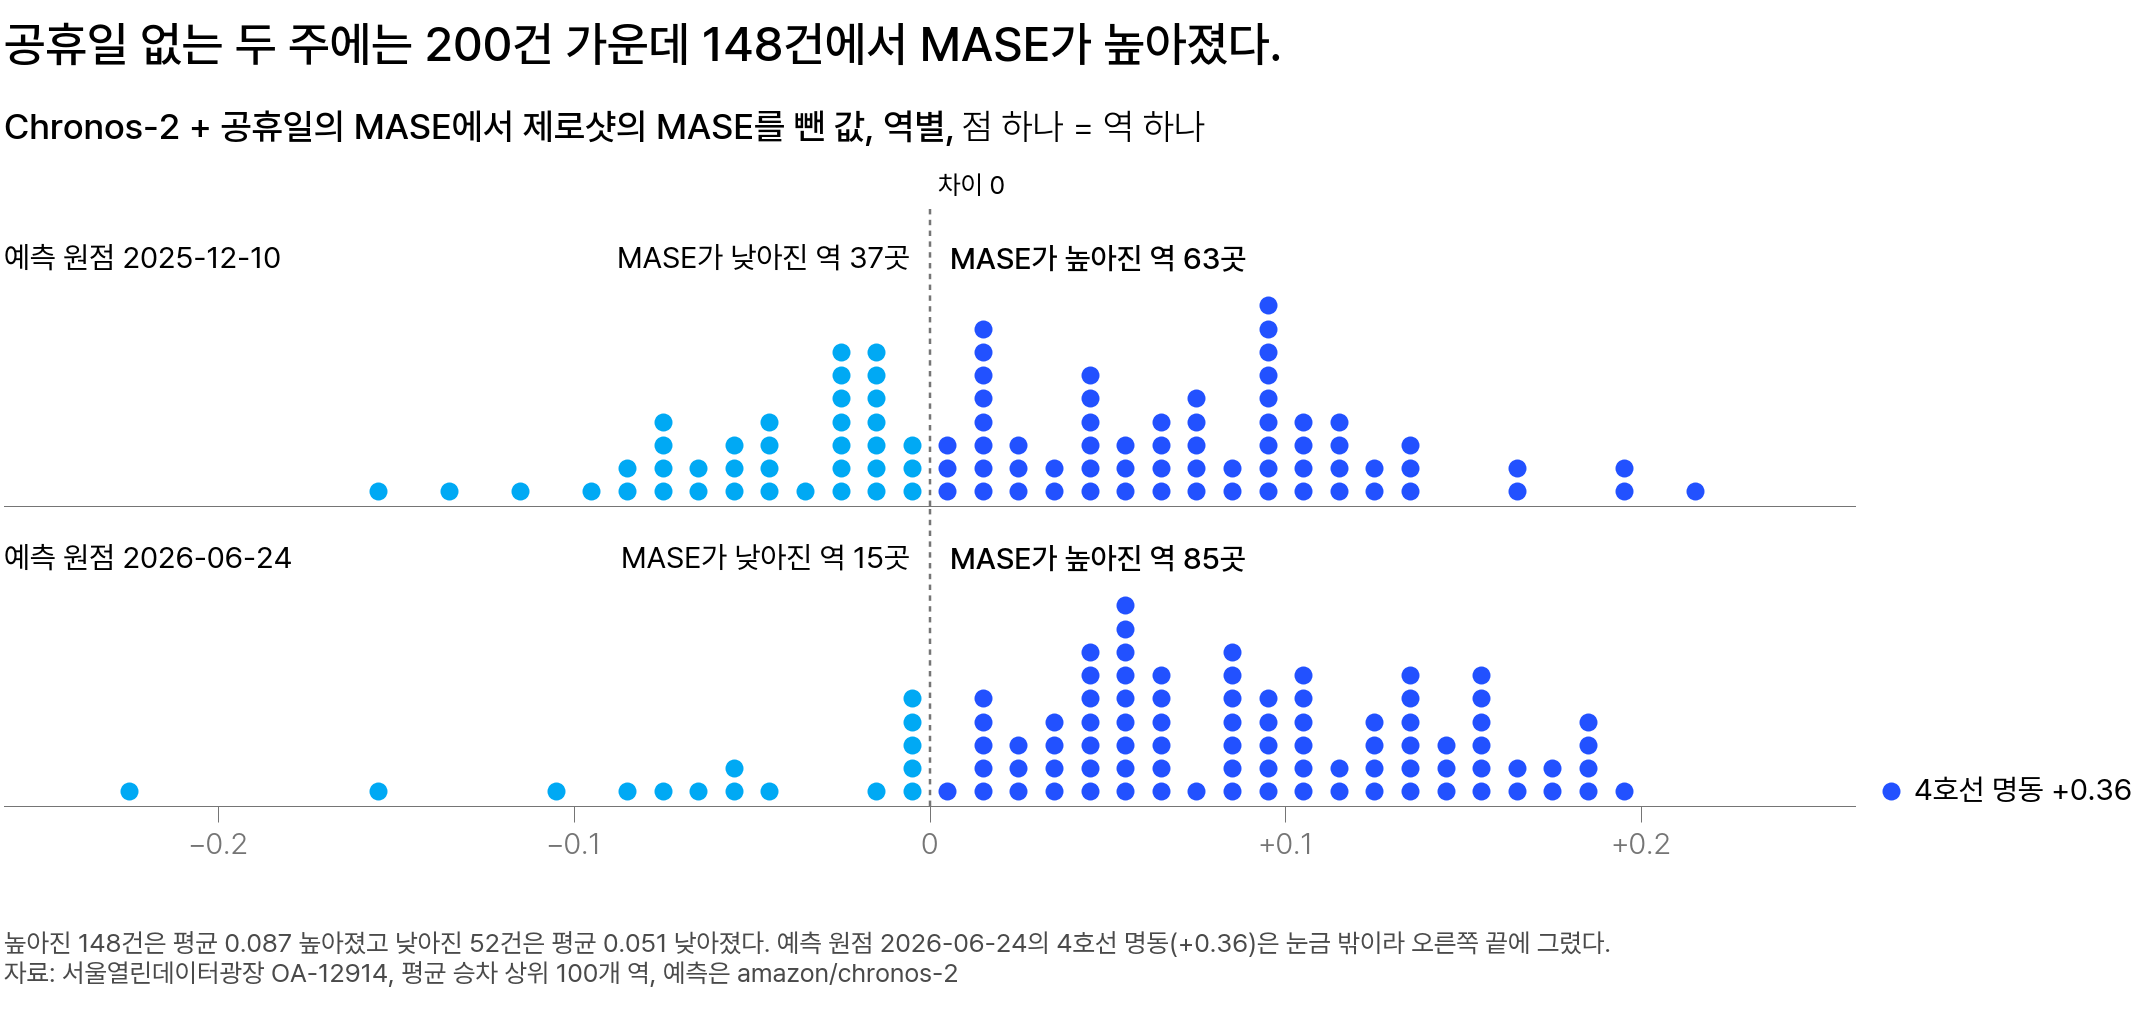

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 역 하나이고, 0 의 오른쪽(파랑)은 Chronos-2 + 공휴일의 MASE 가 제로샷보다 높은 역이다. 두 원점 모두 높아진 역이 더 많다</em></p>

채점 7일의 공휴일 값은 모두 0 이지만, 과거 512일의 공휴일 열이 함께 입력되어 예측이 달라집니다.

다만 왜 높아진 쪽이 많은지는 확인하지 않았습니다. 공휴일이 없는 주는 원점이 2개뿐이라, 다른 주에서도 148건과 비슷한 결과가 나오는지도 아직 모릅니다.

따라서 공휴일이 없는 주에 쓸 모델은 평균으로도 건수로도 여기서 정하지 않습니다. 「4. 정리와 팀 라운드」에서 팀이 근거를 비교해 정합니다.

두 결과를 합치면 평균 MASE 가 1.766 에서 0.742 로 낮아진 까닭을 알 수 있습니다. 공휴일 있는 세 주에서 1.741 낮아졌고, 공휴일 없는 두 주에서는 0.051 높아졌습니다.

즉, 평균이 낮아진 것은 거의 모두 **공휴일 있는 세 주**의 MASE 가 낮아졌기 때문입니다.

<details class="lms-extra"><summary>더 깊이 — 원점별 MASE 와 평일 공휴일 6일의 예측 합</summary>

원점마다 100개 역을 평균한 MASE 입니다. 마지막 열은 제로샷보다 MASE 가 낮아진 역과 높아진 역의 수입니다.

| 예측 원점 | 계절 나이브 | 제로샷 | Chronos-2 + 공휴일 | 낮아진 역 · 높아진 역 |
|---|---:|---:|---:|---|
| 2025-08-13 | 1.069 | 1.115 | 0.621 | 92 · 8 |
| 2025-10-01 | 4.388 | 4.238 | 1.303 | 100 · 0 |
| 2025-12-10(공휴일 없는 주) | 0.419 | 0.279 | 0.309 | 37 · 63 |
| 2026-02-11 | 2.844 | 2.935 | 1.141 | 100 · 0 |
| 2026-06-24(공휴일 없는 주) | 0.471 | 0.263 | 0.335 | 15 · 85 |

원점 2025-08-13 에서 높아진 8개 역 가운데 4호선 명동은 0.814 에서 0.829 로 0.015 높아졌습니다.

2호선 강남은 원점 2025-10-01 에서 4.161 → 1.171, 원점 2026-02-11 에서 3.334 → 1.134 로 낮아졌습니다.

**공휴일 없는 두 주의 200건**

공휴일 없는 두 원점에서 계절 나이브보다 MASE 가 낮은 역은 제로샷이 89개·93개, Chronos-2 + 공휴일이 85개·76개입니다.

두 주 평균으로는 계절 나이브와의 차이가 제로샷 0.174, Chronos-2 + 공휴일 0.123 입니다. 둘 다 시드 범위 0.077 보다 큽니다.

건수에는 얼마나 높아졌는지가 없으므로 크기를 함께 확인합니다. 높아진 148건은 MASE 가 평균 0.087 커졌고, 낮아진 52건은 평균 0.051 작아졌습니다.

200건을 평균하면 두 주 평균 MASE 의 차이와 같습니다.

$$
(148 \times 0.087 - 52 \times 0.051) \div 200 \approx 0.051
$$

이 두 주의 제로샷 MASE 가 0.271 이므로, 0.087 은 그 3분의 1쯤입니다. 148건 가운데 93건은 높아진 크기가 0.1 보다 작습니다.

0.087 은 역마다 비교한 값의 평균입니다. 시드 범위 0.077 은 평균 MASE 의 범위이므로, 두 값을 바로 비교하지 않습니다.

이 두 주에서 역과 날의 조합은 원점 2개 × 역 100개 × 7일 = 1,400건입니다. 그 가운데 실제보다 낮게 예측한 것은 제로샷이 880건으로 62.9%, Chronos-2 + 공휴일이 972건으로 69.4% 입니다.

7일 예측 합 ÷ 실제 합은 제로샷 0.992, Chronos-2 + 공휴일 0.986 입니다. 이 값만으로 MASE 가 높아진 까닭을 말할 수는 없습니다.

Chronos-2 를 쓰는 AutoGluon 의 안내서도 공변량이 언제나 도움이 되는 것은 아니라고 설명합니다([Forecasting with Chronos-2](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-chronos.html)). 공변량을 더 많이 쓴다고 예측이 더 정확해지는 것도 아니라고 함께 설명합니다.

**평일 공휴일 6일의 예측 합**

다음은 공휴일 있는 세 주의 평일 공휴일 6일입니다. 이 6일의 100개 역 예측 합은 제로샷이 실제 합의 2.14배, Chronos-2 + 공휴일이 1.10배입니다.

아래 표는 100개 역 예측 합 ÷ 실제 합을 날마다 계산한 값입니다.

| 날짜 | 제로샷 | Chronos-2 + 공휴일 |
|---|---:|---:|
| 2025-08-15(금) 광복절 | 1.52배 | 0.98배 |
| 2025-10-03(금) 개천절 | 1.66배 | 0.84배 |
| 2025-10-06(월) 추석 | 2.96배 | 1.18배 |
| 2025-10-07(화) 추석 다음날 | 2.28배 | 1.01배 |
| 2026-02-16(월) 설날 전날 | 2.48배 | 1.40배 |
| 2026-02-17(화) 설날 | 2.80배 | 1.50배 |

같은 세 주의 나머지 평일 9일은 제로샷의 예측 합이 날마다 실제 합의 0.97～1.06배였습니다.

역마다 6일의 예측 합 ÷ 실제 합을 보면 이렇습니다.

| 역 | 제로샷 | Chronos-2 + 공휴일 |
|---|---:|---:|
| 2호선 역삼 | 6.61배 | 1.10배 |
| 2호선 강남 | 3.36배 | 1.30배 |
| 경부선 용산 | 1.04배 | 1.00배 |

Chronos-2 + 공휴일에서 가장 큰 역은 3호선 양재 1.38배이고, 12개 역은 1배보다 작습니다.

</details>

### 설 연휴에는 추가 보정이 필요하다 [필수]

공휴일이 있는 주에는 Chronos-2 + 공휴일을 쓰기로 했습니다. 그런데 설 연휴 이틀은 공휴일 열을 입력해도 예측이 실제보다 높습니다.

| 날 | Chronos-2 제로샷 | Chronos-2 + 공휴일 | 실제 승차 인원 |
|---|---:|---:|---:|
| 2월 16일(월, 설 연휴) | 92,202명 | 37,627명 | 21,453명 |
| 2월 17일(화, 설 연휴) | 94,837명 | 37,919명 | 14,973명 |

이틀 모두 예측이 실제보다 1.6만 명 넘게 높습니다.

**왜 실제만큼 낮아지지 않았을까요?** 공휴일 열에서는 설 연휴와 하루 쉬는 공휴일이 같은 1 이기 때문입니다.

가게 예시에서 명절의 20명과 하루 쉬는 휴일의 60명이 같은 비로 반영된 것과 같습니다.

강남역의 512일에 있는 공휴일 26일은 공휴일 열에서 모두 1 입니다. 하지만 승차 인원이 줄어드는 크기는 공휴일마다 다릅니다.

그 크기는 승차 인원을 같은 요일 평균으로 나눈 값으로 비교합니다. 이 값이 0.5배이면 평소 같은 요일의 절반이라는 뜻입니다.

같은 요일 평균은 그날보다 1주 · 2주 앞과 뒤의 같은 요일 4일 가운데 공휴일이 아닌 날의 평균 승차 인원입니다.

올해 설날(2월 17일)의 같은 요일 평균은 92,214명입니다. 위 표의 예측 37,919명과 실제 14,973명을 이 값으로 나눠, 지난해의 두 공휴일과 비교합니다.

- 지난해 광복절의 실제: 0.48배
- 지난해 설날의 실제: 0.14배
- 올해 설날의 예측: 0.41배
- 올해 설날의 실제: 0.16배

즉, 예측 0.41배는 하루 쉬는 공휴일만큼 낮아진 값입니다. 설 연휴만큼 낮아진 값은 아닙니다.

아래 그림은 공휴일 26일을 종류로 나눠 같은 값을 그린 것입니다.

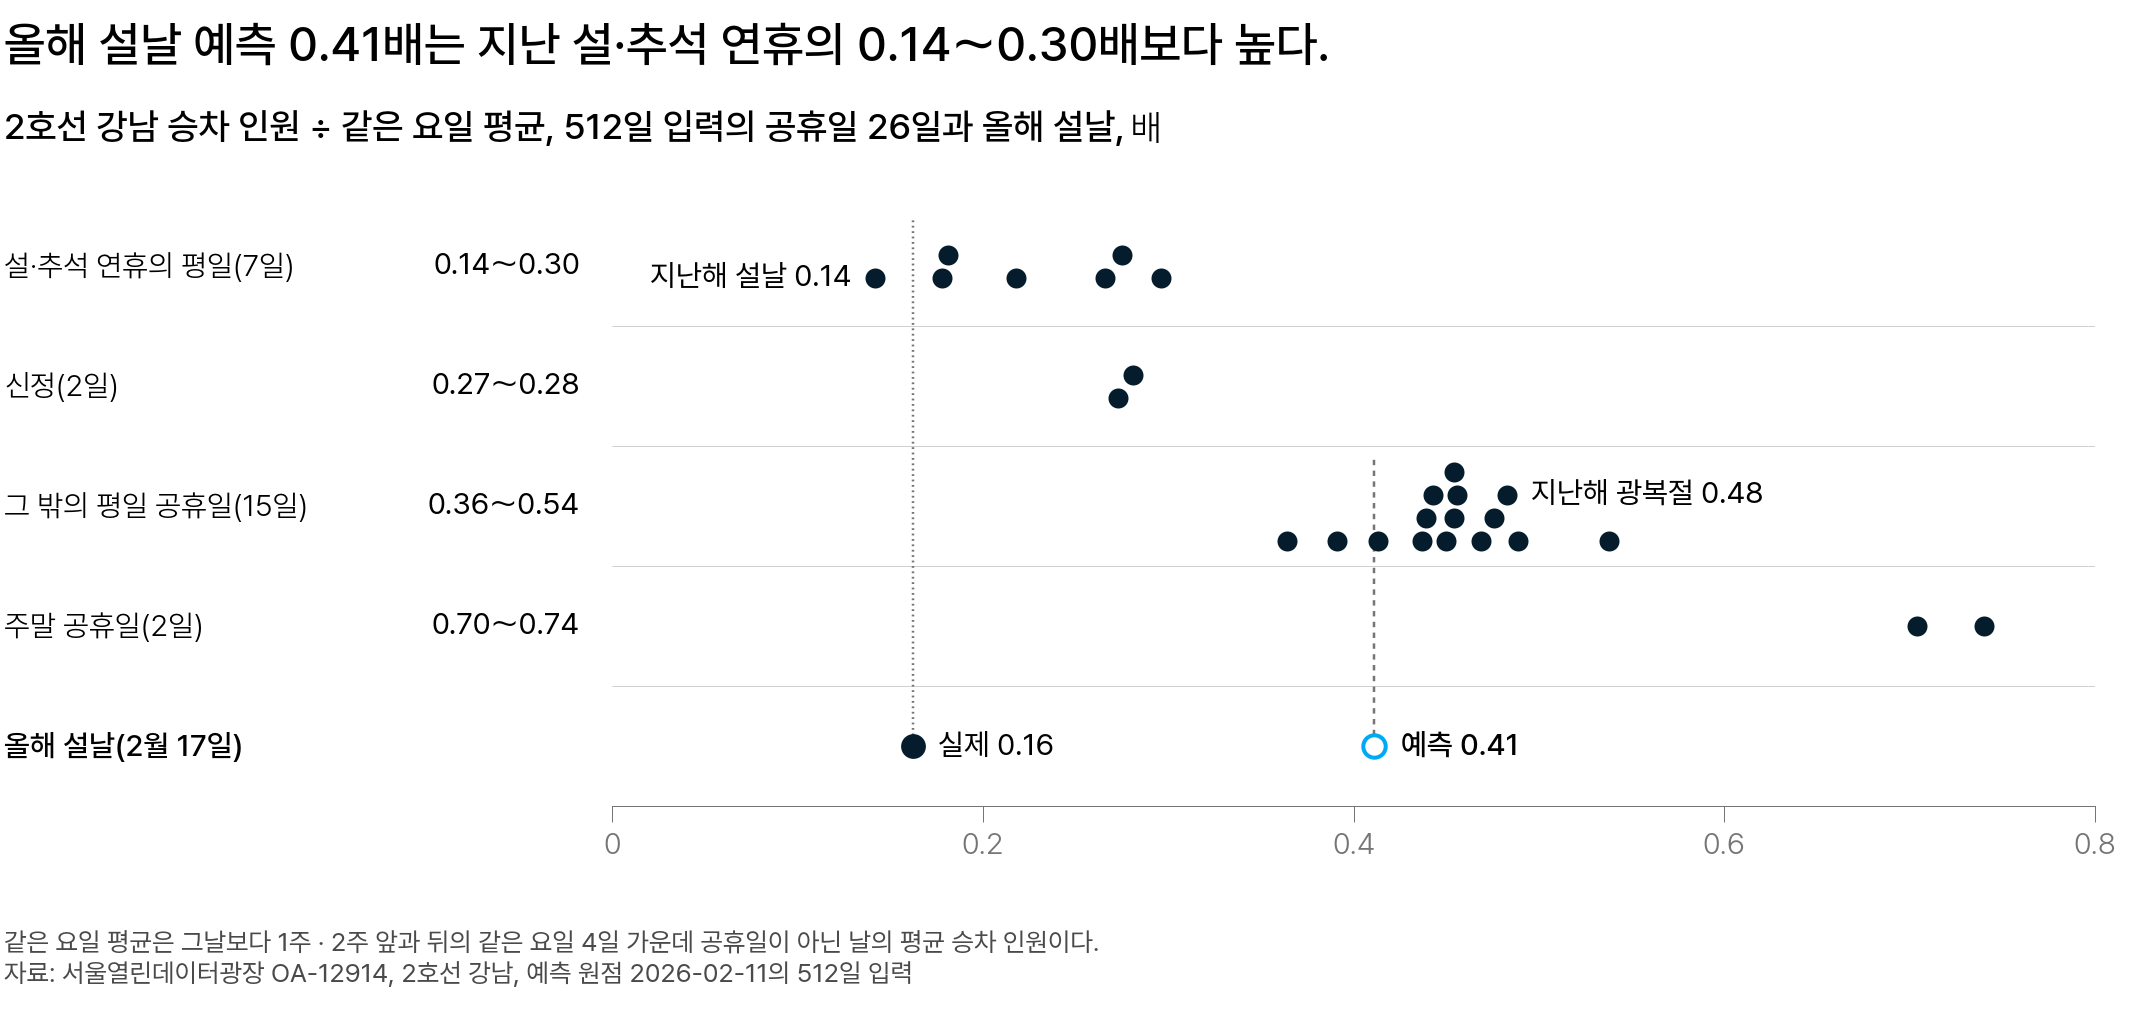

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 공휴일 하루다. 올해 설날의 예측 0.41배는 그 밖의 평일 공휴일과 같은 범위에 있고, 실제 0.16배는 지난 설·추석 연휴와 같은 범위에 있다</em></p>

**설 연휴 이틀의 보정**

그래서 설 연휴 평일 이틀은 예측값을 따로 계산합니다.

$$
\text{보정한 예측값} = \text{1주 전 같은 요일 승차 인원} \times \text{지난해 같은 날의 비}
$$

- 1주 전 같은 요일 승차 인원: 예측 시점에 이미 아는 값 가운데 가장 최근의 같은 요일 값
- 지난해 같은 날의 비: 지난해 그날의 승차 인원을 같은 요일 평균으로 나눈 값

| 강남역의 날 | 1주 전 같은 요일 승차 인원 | 지난해 같은 날의 비 | 보정한 예측값 | 실제 승차 인원 |
|---|---:|---:|---:|---:|
| 2월 16일(설날 전날) | 91,553명 | 0.218배 | 19,959명 | 21,453명 |
| 2월 17일(설날) | 95,750명 | 0.142배 | 13,597명 | 14,973명 |

지난해 같은 날은 지난해 설날 전날과 설날입니다. 설은 해마다 날짜가 달라서, 날짜가 같은 날을 쓰지 않습니다.

식에 올해의 같은 요일 평균은 쓰지 않습니다. 뒤 두 주의 승차 인원이 있어야 구할 수 있어, 예측 시점에는 없는 값이기 때문입니다.

1주 전 같은 요일 승차 인원은 계절 나이브의 예측값과 같습니다. 그래서 이 식을 「계절 나이브 예측 × 지난해 같은 날의 비」라고도 부릅니다.

보정한 예측값은 강남역에서 실제보다 1,494명, 1,376명 낮습니다. 보정하기 전에는 실제보다 16,174명, 22,946명 높았습니다.

100개 역에서 이 이틀만 채점한 MASE 는 2.344 에서 0.451 로 낮아집니다. 100개 역 가운데 98개 역에서 보정한 예측의 MASE 가 더 낮습니다.

광복절, 개천절, 추석 연휴는 보정하지 않습니다. 이 4일은 100개 역의 예측을 모두 더한 값이 실제 승차 인원의 0.84～1.18배로, 이미 실제와 가깝기 때문입니다.

반면 설 연휴 이틀은 1.40배와 1.50배로 남았습니다.

따라서 설 연휴가 있는 주도 Chronos-2 + 공휴일의 예측을 쓰고, **설 연휴 평일 이틀만** 보정한 예측값으로 바꿉니다.

<details class="lms-extra"><summary>자세히 — 강남역 7일과 설 연휴 이틀의 MASE 계산</summary>

역 하나 · 원점 하나의 MASE 는 이렇게 계산합니다.

$$
\text{MASE}_{i,o} = \frac{\text{MAE}_{i,o}}{Q_{i,o}}
$$

- $\text{MAE}_{i,o}$: 역 $i$ 에서 원점 $o$ 의 채점 7일에 절대 오차를 평균한 값(명)
- $Q_{i,o}$: 그 원점 전날까지 계절 나이브가 그 역에서 낸 절대 오차의 평균(명). MASE 의 분모 $Q_i$ 를 원점마다 구한 값

계절 나이브가 평소 내던 오차의 몇 배만큼 틀렸는지를 뜻합니다.

강남역 원점 2026-02-11 의 $Q_{i,o}$ 는 7,761.8명입니다. 절대 오차는 실제와 예측의 차이의 절댓값입니다.

| 날짜 | 실제 승차 인원 | 제로샷의 절대 오차 | Chronos-2 + 공휴일의 절대 오차 |
|---|---:|---:|---:|
| 02-11(수) | 95,623명 | 1,402명 | 1,818명 |
| 02-12(목) | 96,519명 | 1,930명 | 2,981명 |
| 02-13(금) | 95,092명 | 2,682명 | 261명 |
| 02-14(토) | 53,284명 | 14,988명 | 12,001명 |
| 02-15(일) | 30,140명 | 9,524명 | 5,450명 |
| 02-16(월) | 21,453명 | 70,749명 | 16,174명 |
| 02-17(화) | 14,973명 | 79,864명 | 22,946명 |

7일의 절대 오차를 더해 7 로 나누고, 그 값을 $Q_{i,o}$ 로 나눕니다.

| 방식 | 7일의 합 | ÷ 7(MAE) | ÷ 7,761.8(MASE) |
|---|---:|---:|---:|
| 제로샷 | 181,139명 | 25,877.0명 | 3.334 |
| Chronos-2 + 공휴일 | 61,631명 | 8,804.4명 | 1.134 |

설 연휴 이틀의 MASE 는 날짜 표의 마지막 두 행만 평균해 같은 $Q_{i,o}$ 로 나눕니다. 강남역은 제로샷 9.702, Chronos-2 + 공휴일 2.520 입니다.

100개 역을 평균하면 이렇습니다.

| 방식 | 설 연휴 이틀의 MASE |
|---|---:|
| Chronos-2 제로샷 | 8.323 |
| Chronos-2 + 공휴일 | 2.344 |
| 계절 나이브 예측 × 지난해 같은 날의 비 | 0.451 |

셋째 방식의 MASE 는 100개 역 가운데 98개 역에서 Chronos-2 + 공휴일보다 낮습니다. 지난해 같은 날의 비는 역마다 그 역의 값을 씁니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Seoul-metro-211-Seongsu-station-platform-20181122-100608.jpg" alt="2호선 성수역 지상 승강장, 양쪽 스크린도어 사이로 승객 몇 명이 걷는 모습" width="640" height="360"/>
<p align="center"><em>▲ 2호선 성수역 승강장. 공휴일 열을 입력한 뒤에도 설 연휴 이틀의 MASE 가 4.180 으로 100개 역 가운데 가장 컸다 (출처: Wikimedia Commons, Seoul-metro-211-Seongsu-station-platform-20181122-100608.jpg)</em></p>

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Seoul-metro-424-Myeongdong-station-entrance-01-20181124-082338.jpg" alt="눈 내리는 날 4호선 명동역 1번 출구" width="640" height="360"/>
<p align="center"><em>▲ 4호선 명동역 1번 출구. 설 연휴 이틀의 MASE 가 0.384 로 100개 역 가운데 가장 작았다 (출처: Wikimedia Commons, Seoul-metro-424-Myeongdong-station-entrance-01-20181124-082338.jpg)</em></p>

설날 전날(2월 16일)의 비도 같은 방법으로 구합니다. 2월 16일의 같은 요일 평균은 91,938명입니다.

| 강남역 2월 16일 | 승차 인원 ÷ 같은 요일 평균 |
|---|---:|
| Chronos-2 + 공휴일 예측 | 37,627 ÷ 91,938 ≈ 0.41배 |
| 실제 | 21,453 ÷ 91,938 ≈ 0.23배 |
| 지난해 설날 전날(실제) | 0.218배 |

본문 표의 보정한 예측값은 셋째 자리로 반올림한 비 0.218 과 0.142 를 곱해 계산했습니다.

</details>

> **[문제] 설 연휴 이틀의 예측**
>
> 공휴일 열을 입력했는데도 강남역 설 연휴 이틀의 예측은 실제만큼 낮아지지 않았습니다. 그 까닭과, 설 연휴가 있는 주에 어느 예측을 쓸지를 적어 보세요.

### 하차 인원은 미래 입력에 포함하지 않는다 [필수]

하차 인원은 승차 인원과 거의 같은 값입니다. 100개 역 × 4,199일에서 두 값의 상관은 0.990 입니다.

그래서 채점 7일의 하차 인원을 미래 입력에 포함해 백테스트하면 MASE 가 크게 낮아집니다.

| 채점한 주 | Chronos-2 제로샷 | 하차 인원과 공휴일 열을 두 표에 포함한 예측 | Chronos-2 + 공휴일 |
|---|---:|---:|---:|
| 공휴일 있는 세 주 | 2.763 | 0.342 | 1.022 |
| 공휴일 없는 두 주 | 0.271 | 0.158 | 0.322 |

하지만 예측 시점에는 채점 7일의 하차 인원을 알 수 없습니다.

따라서 가운데 열의 0.342 와 0.158 은 실제로 예측할 때는 얻을 수 없는 점수입니다. 가게 예시에서 결제 건수를 함께 쓴 예측과 같은 데이터 누수입니다.

Chronos-2 는 `future_df` 의 열을 모두 미래 공변량으로 받습니다. 이 때문에 하차 열이 있어도 오류가 나지 않고, 점수만 좋아집니다.

> 하차 인원은 과거 공변량이므로 과거 표 `df` 에만 포함하고, 미래 입력 `future_df` 에는 포함하지 않습니다.

실습 미션 2 에서 이 누수가 있는 전임 담당자의 코드를 고칩니다.

<div class="lms-summary">

**정리**

평균 MASE 가 낮아진 것은 공휴일이 있는 세 주에서 크게 낮아졌기 때문입니다. 공휴일이 없는 두 주는 제로샷과의 차이가 시드 범위보다 작습니다.

**할 일**

- 평가표에는 평균과 함께 공휴일이 있는 주와 없는 주의 MASE 를 따로 적습니다
- 평균의 차이가 시드 범위보다 작으면 역마다 비교한 건수를 함께 적습니다
- 설 연휴 평일 이틀은 보정한 예측값으로 바꿉니다
- 하차 인원 같은 과거 공변량은 미래 입력 `future_df` 에 포함하지 않습니다

공휴일 열의 효과는 공휴일이 있는 주에서 나왔고, 없는 주에서는 확인되지 않았습니다.

</div>

> **[문제] 평균이 낮아졌는데도 공휴일이 있는 주와 없는 주를 나누는 까닭**
>
> Chronos-2 + 공휴일의 원점 5개 평균 MASE 는 1.766 에서 0.742 로 낮아졌습니다. 그런데도 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠서 다시 채점해야 하는 까닭을 두 문장으로 적어 보세요.

## 4. 정리와 팀 라운드

다음 주 역별 인력 예측에 Chronos-2 + 공휴일을 쓸까요?

평일 공휴일이 있는 주에는 씁니다. 공휴일이 없는 주에 쓸지는 아래 팀 라운드에서 정합니다.

### 공변량을 추가하기 전에 확인할 다섯 가지 [필수]

새 열을 공변량으로 추가하기 전에 다섯 가지를 차례로 확인합니다.

**질문 1. 예측하려는 값인가?** 승차 인원처럼 예측하려는 값이면 미래 입력에 포함하지 않습니다.

**질문 2. 예측 시점에 예측할 날의 값을 이미 알고 있는가?** 알면 미래 공변량으로 두 표에 모두 포함합니다. 모르면 과거 공변량으로 과거 표에만 포함합니다.

**질문 3. 과거 표에 같은 상황이 있는가?** 과거 표에 공휴일이 하루도 없으면, 공휴일에 승차 인원이 얼마나 줄어드는지 알 수 있는 값이 없습니다.

**질문 4. 추가한 뒤 조건을 나눠서 다시 채점했는가?** 전체 평균 하나로 정하지 않고, 추가한 열로 조건을 나눠서 채점합니다. 공휴일 열을 추가했다면 공휴일이 있는 주와 없는 주로 나눕니다.

**질문 5. 차이가 시드 범위보다 큰가?** 두 모델의 평균 MASE 차이가 시드 범위 0.077 보다 작으면 어느 모델이 더 낫다고 하지 않습니다. 이때는 역마다 비교한 건수를 함께 봅니다.

반대로 차이가 0.077 보다 커도 바로 쓰지 않는 경우가 있습니다. **[참고] 글로벌 MLP(MAE 손실) + 공휴일**이 그 예입니다. 글로벌 MLP 를 공휴일 열과 함께 다시 학습한 모델입니다. 평가표에는 Chronos-2 + 공휴일 다음의 일곱째 방식으로 적습니다.

공휴일 있는 세 주의 MASE 는 Chronos-2 + 공휴일이 1.022, [참고] 모델이 0.908 입니다. [참고] 모델이 0.114 낮습니다. 그런데 시드 0 으로 한 번만 학습한 값이라, 이 차이가 시드 때문인지 알 수 없습니다.

따라서 시드 0～4 로 다시 학습해도 차이가 0.077 보다 큰지 확인하기 전까지 쓰지 않습니다.

<details class="lms-extra"><summary>더 깊이 — 공휴일 열의 출처와 평가표에 함께 적는 것</summary>

공휴일 열은 holidays 0.103 의 한국 달력에서 그날이 공휴일이면 1, 아니면 0 인 열입니다. 주말인 공휴일도 1 입니다. 원점 5개의 `future_df` 공휴일 열은 이렇습니다.

| 예측 원점 | 공휴일 열 7개 | 1 인 날 |
|---|---|---|
| 2025-08-13 | [0, 0, 1, 0, 0, 0, 0] | 08-15(금) 광복절 |
| 2025-10-01 | [0, 0, 1, 0, 1, 1, 1] | 10-03(금) 개천절, 10-05(일)～10-07(화) 추석 연휴 |
| 2025-12-10 | [0, 0, 0, 0, 0, 0, 0] | 없음 |
| 2026-02-11 | [0, 0, 0, 0, 0, 1, 1] | 02-16(월)·02-17(화) 설 연휴 |
| 2026-06-24 | [0, 0, 0, 0, 0, 0, 0] | 없음 |

평가표의 모델 이름 옆에는 아래를 함께 적습니다.

| 적을 것 | Chronos-2 + 공휴일에서 |
|---|---|
| 포함한 열과 표 | `holiday` 를 과거 표 `df`(512일)와 미래 입력 `future_df`(7일)에 포함한다 |
| 포함하지 않은 열 | 하차 인원·실측 기온(과거 공변량) |
| 채점 | 공휴일이 있는 주와 없는 주의 MASE 1.022 · 0.322, 300건 가운데 292건에서 낮아짐 · 200건 가운데 148건에서 높아짐 |
| 예측 전에 확인할 것 | 다음 주 7일에 새로 정해진 임시공휴일 |

</details>

<details class="lms-extra"><summary>자세히 — [참고] 모델의 입력과 원점별 차이</summary>

[참고] 모델은 MAE 손실로 학습했고, 같은 원점 5개를 채점해 평가표에 [참고] 로 표시합니다.

[참고] 모델의 입력은 63개입니다. 원점 전 28일의 승차 인원 28개와, 그 28일에 예측할 7일을 더한 35일의 공휴일 여부 35개입니다.

아래 표는 평가표의 세 열에서 Chronos-2 + 공휴일과 비교한 것입니다.

| 평가표의 열 | Chronos-2 + 공휴일 | [참고] 모델 | 차이 | 0.077 과 비교 |
|---|---:|---:|---:|---|
| 평균 MASE | 0.742 | 0.682 | 0.060 | 작다 |
| 공휴일 없는 두 주 | 0.322 | 0.344 | 0.022 | 작다 |
| 공휴일 있는 세 주 | 1.022 | 0.908 | 0.114 | 크다 |

차이가 0.077 보다 큰 것은 공휴일 있는 세 주 하나입니다. 나머지 둘은 차이가 있다고 보지 않습니다.

공휴일 있는 세 주의 MASE 는 MLP(MAE 손실)가 2.717, 공휴일 열을 함께 입력한 [참고] 모델이 0.908 입니다.

학습하는 모델은 시드에 따라 MASE 가 달라집니다. 시드 범위 0.077 도 공휴일 열이 없는 MLP 를 시드만 바꿔 다시 학습해 얻은 값입니다.

공휴일 있는 세 주의 차이 0.114 를 원점마다 보면 이렇습니다.

| 예측 원점 | 두 모델의 MASE 차이 | 0.077 과 비교 |
|---|---|---|
| 2025-08-13 | [참고] 모델이 0.025 높다 | 작다 |
| 2025-10-01 | [참고] 모델이 0.022 낮다 | 작다 |
| 2026-02-11 | 1.141 − 0.797 = 0.344 만큼 [참고] 모델이 낮다 | 크다 |

이 차이는 거의 모두 설 연휴가 있는 원점 2026-02-11 한 주에서 나왔습니다. 세 주 가운데 한 주의 결과로 생긴 차이입니다.

원점 2026-02-11 의 차이 0.344 는 위 표에서 [참고] 모델의 공휴일 없는 두 주 값 0.344 와 우연히 같은 수입니다.

이 차이를 세 원점으로 나누면 0.344 ÷ 3 ≈ 0.115 라, 세 주 평균의 차이 0.114 의 거의 전부입니다.

</details>

### 결론: 공휴일이 있는 주와 없는 주에 무엇을 쓰는가 [필수]

서울 지하철 역별 인력 예측의 결론을 표로 정리합니다.

| 상황 | 사용할 예측 | 근거 |
|---|---|---|
| 평일 공휴일이 있는 주 | Chronos-2 + 공휴일 | 공휴일 있는 세 주의 MASE 2.763 → 1.022, 300건 가운데 292건에서 낮아짐 |
| 그 가운데 설 연휴 평일 이틀 | 1주 전 같은 요일 승차 인원 × 지난해 같은 날의 비 | 100개 역 이틀의 MASE 2.344 → 0.451 |
| 공휴일이 없는 주 | 팀 라운드에서 정한다 | 0.271 대 0.322, 차이 0.051 은 시드 범위 0.077 보다 작음. 둘 다 계절 나이브 0.445 보다 낮음 |
| 하차 인원을 미래 입력에 포함한 백테스트 | 쓰지 않는다 | 데이터 누수 |
| [참고] 글로벌 MLP(MAE 손실) + 공휴일 | 아직 쓰지 않는다 | 시드 0 으로 한 번만 학습한 값 |

첫 행의 근거를 그림으로 한 번 더 확인합니다. 아래 그림은 계절 나이브를 뺀 여섯 방식의 MASE 가 같은 기간의 계절 나이브 MASE 의 몇 배인지를 비교합니다. 이 배수가 1 보다 작으면 같은 기간의 계절 나이브보다 오차가 작다는 뜻입니다.

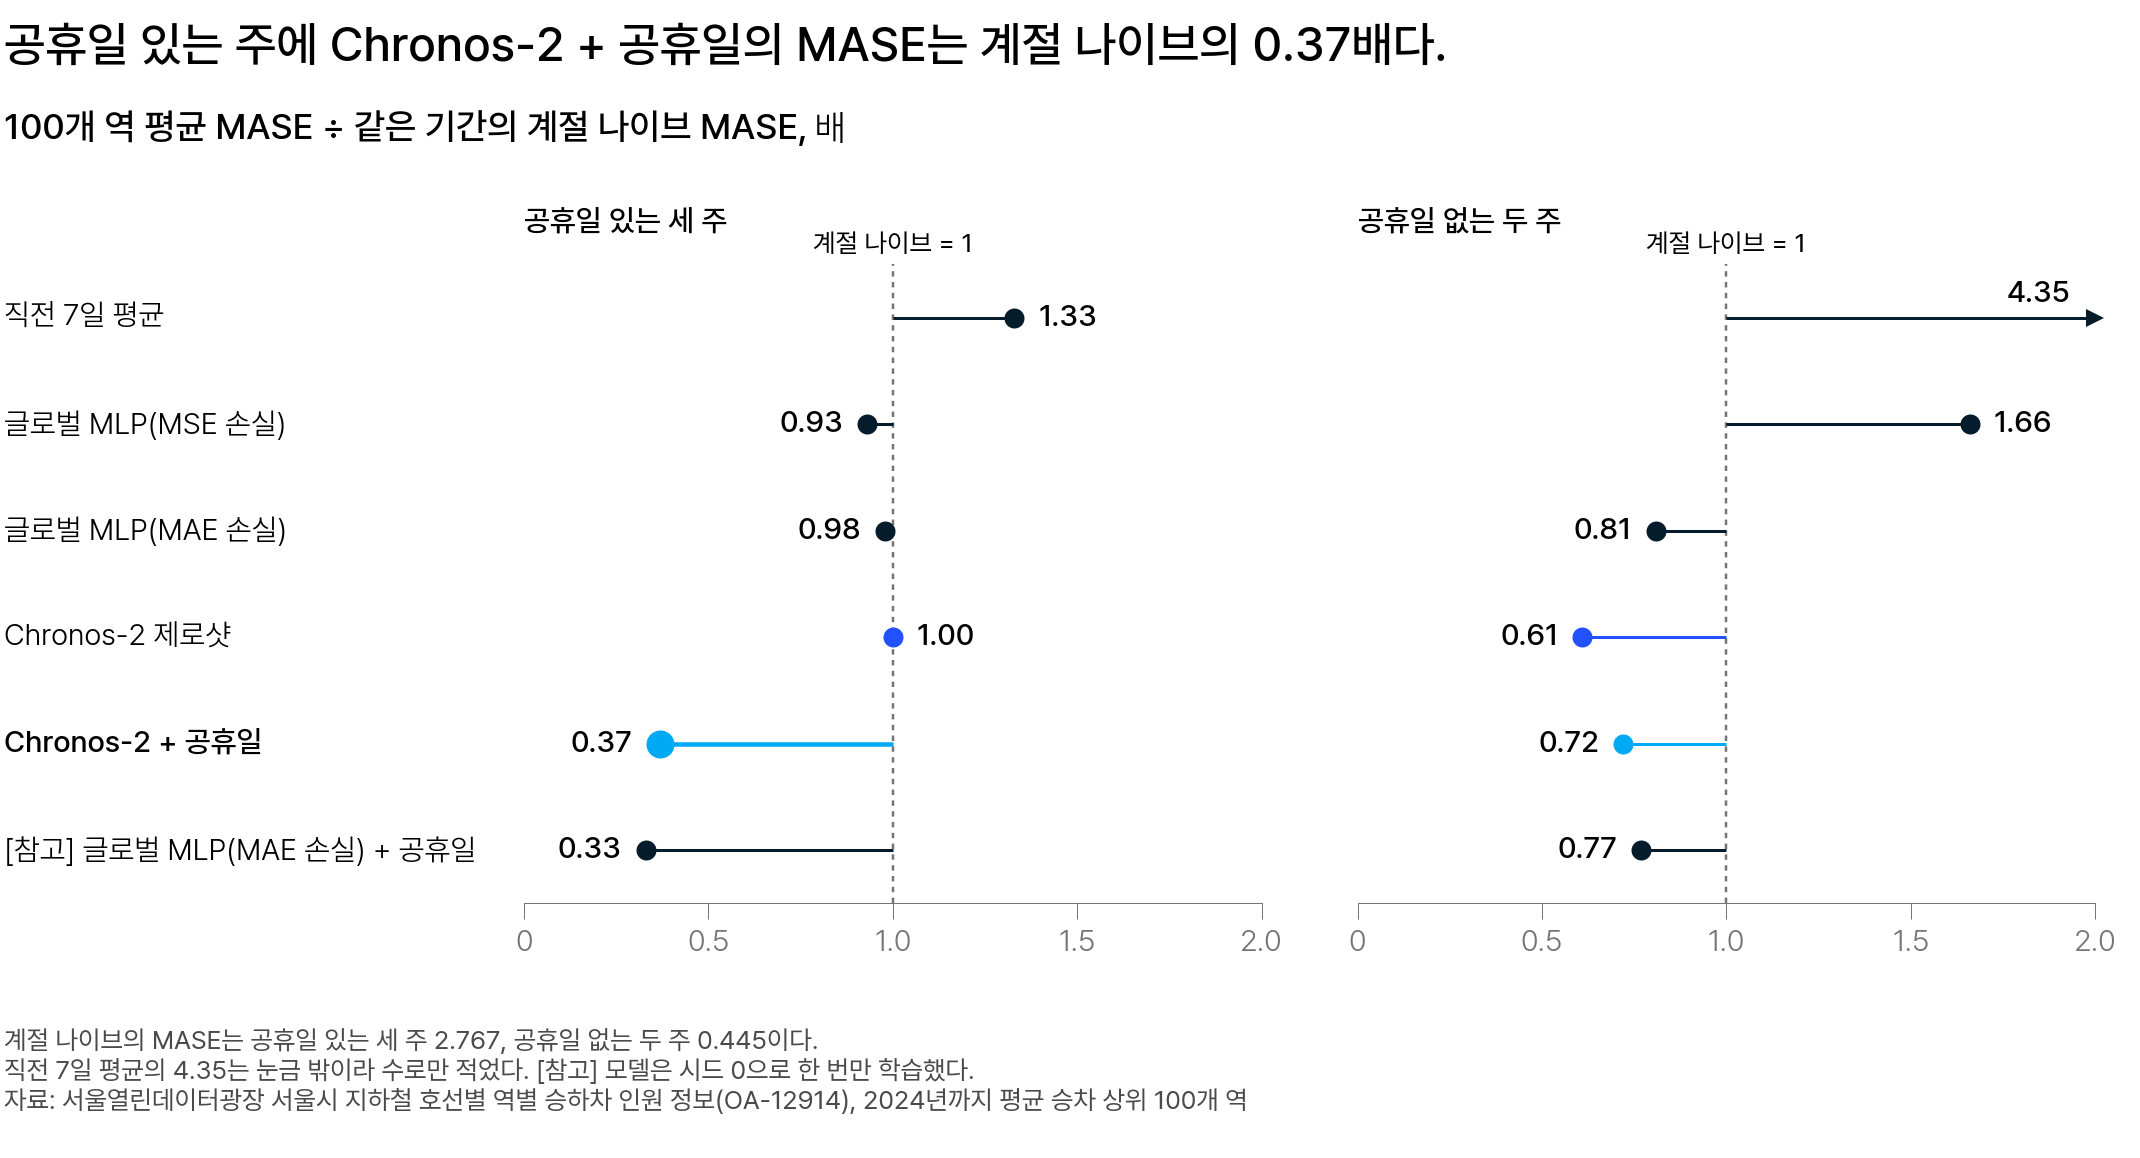

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 공휴일 있는 세 주에는 공휴일 열을 입력한 두 방식만 계절 나이브의 0.4배보다 낮고, 입력하지 않은 네 방식은 0.93～1.33배다</em></p>

가장 중요한 원칙은 하나입니다.

> 공변량은 많이 추가하는 것보다, 예측 시점에 실제로 알 수 있는 값만 입력하는 것이 중요합니다.

<details class="lms-extra"><summary>자세히 — 가변수와 평가표에서 채점하지 않은 두 모델</summary>

공휴일 열처럼 「그렇다」를 1, 「아니다」를 0 으로 나타내는 열을 **가변수(dummy variable)** 라고 부릅니다. 시계열 예측 교재 [fpp3 7.4](https://otexts.com/fpp3/useful-predictors.html) 에서도 회귀 모형에 공휴일 여부를 가변수로 입력합니다.

<img src="https://otexts.com/fpp3/regression_files/figure-html/fig-beerlm2-1.png" alt="호주 분기 맥주 생산량과 추세·분기 가변수 회귀의 적합값" width="640" height="395"/>
<p align="center"><em>▲ 호주 분기 맥주 생산량(검은 선)과 추세·분기 가변수로 맞춘 회귀의 적합값(주황 선). 분기마다 값이 0 과 1 뿐인 열이 해마다 되풀이되는 높낮이를 나타낸다 (출처: Hyndman &amp; Athanasopoulos, Forecasting: Principles and Practice 3rd ed., §7.4)</em></p>

평가표에서 채점하지 않은 모델은 둘입니다.

하나는 설·추석 연휴 열을 따로 포함한 모델입니다(「2. 공휴일 열과 미래 입력」).

다른 하나는 여러 역을 한 그룹으로 둔 모델입니다. 이 수업에서는 역마다 그룹이 따로입니다.

`predict_df` 의 `cross_learning=True` 는 한 번에 전달한 계열 전체를 한 그룹으로 만듭니다. 호선별로 역을 나눠 그룹을 만드는 것은 이 인자로 정할 수 없습니다.

</details>

<div class="lms-summary">

**정리**

공휴일 열을 입력하자 공휴일이 있는 주의 예측이 크게 좋아졌습니다. 공휴일이 없는 주에는 차이가 시드 범위보다 작아, 쓸 모델을 아래 팀 라운드에서 정합니다.

**할 일**

- 임시공휴일이 새로 정해졌는지 예측할 때마다 확인합니다
- 평가표에는 공휴일이 있는 주와 없는 주의 MASE 와 역마다 비교한 건수를 함께 적습니다

공휴일 열을 입력한 Chronos-2 는 평일 공휴일이 있는 주에 씁니다.

</div>

### 팀 라운드: 운영팀에 전달할 예측 방식 [필수]

**아래 질문의 답은 수업에서 팀이 함께 정합니다.** 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 다음 주부터 운영팀에 어느 방식의 예측을 전달할까**
>
> 역 운영팀은 다음 주부터 처음으로 매주 수요일 아침에 100개 역의 7일 예측을 받습니다. 수요일부터 7일씩 세면 2026년 52주 가운데 39주가 평일 공휴일이 없는 주입니다. 운영팀은 주마다 방식이 달라지면 그 까닭을 예측과 함께 적어 보내 달라고 합니다. 후보 셋의 MASE 는 원점 5개 평균, 공휴일 없는 두 주, 공휴일 있는 세 주 차례로 이렇습니다.
> 
> - **Chronos-2 제로샷** 1.766 · 0.271 · 2.763
> - **Chronos-2 + 공휴일** 0.742 · 0.322 · 1.022
> - **글로벌 MLP(MAE 손실) + 공휴일** 0.682 · 0.344 · 0.908. 평가표에 [참고] 로 표시한 모델입니다
> 
> 시드 범위는 0.077 이고, 계절 나이브는 공휴일 없는 두 주에서 0.445 입니다. 두 Chronos-2 를 역마다 비교하면, 공휴일 없는 두 주의 200건 가운데 148건에서 제로샷의 MASE 가 더 낮았습니다. 원점별로는 제로샷이 더 낮은 역이 100개 가운데 63개와 85개입니다. 같은 두 주에서 실제보다 낮게 예측한 역과 날의 조합은 제로샷이 62.9%, Chronos-2 + 공휴일이 69.4% 였습니다. 설 연휴 평일 이틀의 보정은 어느 관점에서나 그대로 둡니다.
> 
> 팀 안에서 의견이 셋으로 나뉘었습니다.
> 
> - **관점 A: 모든 주에 Chronos-2 + 공휴일을 쓴다.** 공휴일 없는 두 주의 차이 0.051 은 시드 범위 0.077 보다 작아 차이가 있다고 보지 않는다. 방식이 하나라, 주마다 까닭을 따로 적어 보낼 일이 없다.
> - **관점 B: 모든 주에 글로벌 MLP(MAE 손실) + 공휴일을 쓴다.** 평균 MASE 가 0.682 로 후보 가운데 가장 낮다. 공휴일 있는 세 주에서는 Chronos-2 + 공휴일보다 0.114 낮아, 차이가 시드 범위 0.077 을 넘는다.
> - **관점 C: 달력으로 나눠 쓴다.** 평일 공휴일이 없는 주에는 제로샷을, 있는 주에는 Chronos-2 + 공휴일을 쓴다. 200건 가운데 148건에서 제로샷이 더 낮았고 두 원점의 방향이 같다. 실제보다 낮게 예측한 비율도 제로샷이 더 작다. 평일 공휴일이 있는지는 예측 시점에 달력으로 안다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.